# ViHSD — Nghiên cứu Thực nghiệm PhoBERT với Bộ từ điển Teencode của Cô


## 1. Cài đặt các thư viện môi trường cần thiết


In [29]:
# 1. Cài đặt môi trường Colab (chuẩn theo notebook gốc)
%pip install -q "transformers==4.57.1" "datasets==3.6.0" "accelerate==1.10.1" "pyvi==0.1.1"


## 2. Khai báo thư viện, thiết lập môi trường và seed (kế thừa y hệt notebook gốc)


In [30]:
# 2. Khai báo thư viện, thiết lập môi trường và seed (kế thừa y hệt notebook gốc)
import os, io, re, json, time, random, hashlib, zipfile, unicodedata, html, gc, platform
from pathlib import Path
from urllib.request import urlopen
import numpy as np
import pandas as pd
from pyvi import ViTokenizer
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import torch
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    Trainer, TrainingArguments, DataCollatorWithPadding, set_seed
)
from datasets import Dataset

ROOT = Path('vihsd_teencode_co_experiment')
ROOT.mkdir(exist_ok=True)
RUN_DIR = ROOT / time.strftime('%Y%m%d_%H%M%S')
RUN_DIR.mkdir(exist_ok=False)

LABELS = [0, 1, 2]
NAMES = ['CLEAN', 'OFFENSIVE', 'HATE']
REPO_COMMIT = '826ef5efdda8f397e8b76b1ac26e05edda20ded6'
SEEDS = [42]

# Điểm PhoBERT baseline đối chứng từ notebook gốc
BASELINE_FULL_MACRO_F1 = 0.6820
BASELINE_UNSEEN_MACRO_F1 = 0.6758

def save_json(name, obj):
    (RUN_DIR / name).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def metrics(y, p):
    per = f1_score(y, p, labels=LABELS, average=None, zero_division=0)
    return dict(macro_f1=float(per.mean()), weighted_f1=float(f1_score(y, p, labels=LABELS, average='weighted', zero_division=0)),
                accuracy=float(accuracy_score(y, p)), **{f'f1_{n}': float(v) for n, v in zip(NAMES, per)})

print("Thư mục thực nghiệm:", RUN_DIR)
print("Baseline đối chứng: Full Test Macro F1 = 68.20%, Unseen Test Macro F1 = 67.58%")


Thư mục thực nghiệm: vihsd_teencode_co_experiment/20261112_181137
Baseline đối chứng: Full Test Macro F1 = 68.20%, Unseen Test Macro F1 = 67.58%


## 3. Tải đúng dữ liệu, lưu hash và kiểm tra rò rỉ (y hệt notebook gốc)


In [31]:
# 3. Tải đúng dữ liệu, lưu hash và kiểm tra rò rỉ (y hệt Cell 7 của notebook gốc)
DATA_URL = f'https://raw.githubusercontent.com/sonlam1102/vihsd/{REPO_COMMIT}/data/vihsd.zip'
archive = ROOT / 'vihsd_pinned.zip'
if not archive.exists():
    with urlopen(DATA_URL, timeout=60) as r:
        archive.write_bytes(r.read())
blob = archive.read_bytes()
EXPECTED_SHA256 = '1d823c4c86a8aede83555c64da4e1be24146967aac6b30cdaf8603d4910f328d'
assert hashlib.sha256(blob).hexdigest() == EXPECTED_SHA256, 'ZIP khác bản đã kiểm tra; xác minh nguồn trước khi tiếp tục.'

frames = {}
with zipfile.ZipFile(io.BytesIO(blob)) as z:
    for split in ['train', 'dev', 'test']:
        df = pd.read_csv(z.open(f'vihsd/{split}.csv'), keep_default_na=False)
        assert {'free_text', 'label_id'} <= set(df.columns)
        df = df.rename(columns={'free_text': 'text', 'label_id': 'label'})
        assert df.label.isin(LABELS).all()
        df['label'] = df.label.astype(int)
        df['text'] = df.text.astype(str)
        df['id'] = [f'{split}_{i:06d}' for i in range(len(df))]
        frames[split] = df[['id', 'text', 'label']].copy()

def text_key(s):
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', str(s))).strip()

keys = {s: f.text.map(text_key) for s, f in frames.items()}
audit = {s: {'rows': len(f), 'empty': int(keys[s].eq('').sum()), 'duplicate_rows': int(keys[s].duplicated().sum())} for s, f in frames.items()}
overlaps = {a + '/' + b: len((set(keys[a]) & set(keys[b])) - {''}) for a, b in [('train', 'dev'), ('train', 'test'), ('dev', 'test')]}

seen_text = set(keys['train']) | set(keys['dev'])
UNSEEN_MASK = (~keys['test'].isin(seen_text) & keys['test'].ne('')).to_numpy()
manifest = dict(url=DATA_URL, commit=REPO_COMMIT, sha256=EXPECTED_SHA256, audit=audit, overlap_unique_text=overlaps,
              test_unseen_text_rows=int(UNSEEN_MASK.sum()), policy='Preserve original splits; also report Test subset unseen in Train/Dev')
save_json('data_manifest.json', manifest)

display(pd.DataFrame(audit).T)
print('Trùng chéo:', overlaps)
print('Test chưa thấy trong Train/Dev:', int(UNSEEN_MASK.sum()), '/', len(UNSEEN_MASK))
df_train, df_dev, df_test = [frames[s] for s in ['train', 'dev', 'test']]
y_train, y_dev, y_test = df_train.label.to_numpy(), df_dev.label.to_numpy(), df_test.label.to_numpy()
display(df_train.label.value_counts().reindex(LABELS).rename(index=dict(zip(LABELS, NAMES))))


,rows,empty,duplicate_rows
train,24048,2,1504
dev,2672,0,22
test,6680,0,106


Trùng chéo: {'train/dev': 321, 'train/test': 787, 'dev/test': 91}
Test chưa thấy trong Train/Dev: 5796 / 6680


,count
label,
CLEAN,19886
OFFENSIVE,1606
HATE,2556


## 4. Đọc và kiểm tra cấu trúc bộ từ điển Teencode của Cô (Chỉ xét 2 cột: 'Teencode' và 'Nghĩa')


In [32]:
# 4. Đọc và kiểm tra từ điển Teencode của Cô (CHỈ XÉT 2 CỘT: 'Teencode' VÀ 'Nghĩa')
import os, re, gzip, base64
import pandas as pd
from IPython.display import display

DICT_FILENAME = 'teencode_co.csv'

if not os.path.exists(DICT_FILENAME):
    print(f"Khởi tạo sẵn file {DICT_FILENAME}...")
    with open(DICT_FILENAME, 'wb') as f:
        f.write(gzip.decompress(base64.b64decode("H4sIABgB9moC/519XW/cRtbmvQD9B6JvbA/q3bZkO/Ys8F7EzsQeOPFkYiGT2Ts2m2oyzY82m2xLudrAGARBEGSM7GAQBMFYEbweJTGcxBkEljDIRTv+H9o/sH9hn+ecKrLYkoPFe+FWN8kqVp06H8/5qPL/Pfp5K46LqBzH5tYkeX4Qrq8lTdKYabJ8GuF7anbSIoiS5YMyGAbRi++Oj75M19cWx0dfpKmRP8GLvTQ4WyTHhw+Lc2gSGnzdHx4ffRMk6C5tzO7y62ZYJ8uviiA/Pnxcs9/I1Onx4c/FJCjQMBqOmuOjz4r1tXk5N9Hx0UEznKKbA7wbt2frayFeF9p3TY6PPkn5qhTja8cU57mJczcSvmmvSIbFLwfFBM8WyfLbpjFFkh4ffdB4453XVTzHO5/fw1hqXH1aTNbXRnGWTmMzxdP3mqBIXnyH18UmiZM4YNNn7FG6Oq3PKEmzzNRoFUzS5X6hRLVUDezz62t1g0nhQ2dVHx99HxTLp5zZnWa5F4aGf7xuiwmIWUx0wgGpGpzNlk9lfkmYG/wLctDxfkFqP44SjhmjbknUpGb5I14Fmu7nmOxyT1csff99E/EX2h0f/SMYLx/gaQzogyIx9fLbIsHwuvU7p/NxbBKcVVpLV1h++7qgLmWhI6MrbFlqOp22T5y19L2xfMCBNHcbM9IrNZ/Yx4qMj4/+EpCSL/a4LuXdEhTA64SMy6+L1QdAShDVY8mgHVxelmPM5ivMvOI1PL1IRzEn8SPehD+Ph0oZLNoehhrltYnKPI+LejgSKmQN5o/lzMM0A7PhE09RePLl/jDDvRn65pPra3fjkcG/eVrHmPTyn6XhxzB6sReAxp+DvmWRGfxLi1i+46/BwI6+j4K62aVskJHiaKpcyFFDnO6m26nhB9Ynxpo/v8/OQIzl0xzMnIQV1jtJw2B+fHgEks7wBFl72MyyMhyvr+E9U1yTFRD6Hn6DF1ULU8WLNL47fH4ffJAICSB1s5mBMOo6PCTFqijHk0qV8RCSuJ8Gy3+vr00qM6nKZja0I5mUuamFIJjt/myI34Fj3fW17ZHZDqN4VJZTzGMEUZElGC33wDPjKsxDI5/DKAEpjj4sgmz5LA928IEhLL+1gw3OYjXPcRmb9spI1Aol+egeblXxDLdm2e6Qi74fZDqAcDzmS7/Oh1M8XgcjMsT62qyc12YE7g+UakKBbNfSgMtydK8Y6r1gynlH29AdZbENHZKWxRxyUoUikO9n5v0ww3Squ+3YFqm8DHR5QiEqt7d7q867UHV3KvPHtwOyFQYUVnURV7LM9yFS4MuhjDWIls8whigBq3NRoayczEdJWBsy/xOQISW3plBwo+OjTzn7PXJsEcUVJgpd8bc0SJY/hKLUyPPzuhnvQoMffQK5lh/BOKxjjrapTYUHJyXoM6xEgJ/f52KmO2Z+fPQ4ZPd/xwUuK0d8+FONAeIa1jicmImOKBHGnNdltWvkUyV0gtXdd6IxykrwPdoe/sTxl4vYLEQj1MGdJoTCwZWgpM6YpIs4vBvuktl+QidQmQ+Gc6pSSs2HXNPczKp0gUkEOVYpnMRWrtLCyN8gLYaTZHmAoT2/B/5KRyYtRuXO0KfhYq7WDrJcWo2Br923pP2alMWk/REleMeL72hWecF7vsm9H10T6ET9C8F82FClllOva7/nnbZrNO/ad5Y4dq8Y2gfxou6tvRGMatde5AcmejpzV2a05ykNXgi2Wh6AFUTDrq8dHz0KDT/wVl8pi70N9WlvQGFisDh4jrfjtq+eupamcWFv4mu82stdfXeRlKW91TdNAB4c1De0b99i4bBuh493IYcGPPsZWiZmAtb4EiLa3lo+S93drClM1mDieEXOKbz4DjTIlw/AxBVQS0U+/AKSUicwp1RcMpiVRyfuHXVStk9FWDHCEQyhAMfiInRiiPePEiidr3YDNy6Oyh+bHZy/thAD7QBf0PPE9Vw1pzyNQey6QbxnJiRLURcyYJHHn4E7HpQCaQTOAFlgUPJrFJaBuxLD5EEaC5MTgHnqPDQhTV5NgshLcvDz6kMR5fnoY3RsrLYNI7YL7GXAjS8MP/Aopt4Y+aT2msK8ik0NY2nAUYwK7WXoDzBvn2zs3d2yIW6qww431SHf/J7/apii7qd0X4elwb/1tef3I2st9yP+mhpf+49Xbqa9uxFMw/Kp3NjtN1t5MMtNtnyQ80b/wXxOMlLrPL8PDYoPAadpXBuV05Pq4vjoo8YkgqL45NQ4gR53HXBh3SOzEMaBnKB4CyBmLx3yInR0lgLayOdQYQ0oxN4a2lWaNNNDC/P0/ZjgfW84pSUKIrE286ysZen/PpwDPj3EULJwZGYwO3xfOIIFaQCXaTAewUzDvBSwx0efYxXSGQlw+Kwc8ivEajd3DQVcoGkFDZFjLn8poKiWj3GlrHIHI9H2GzJAWcdmkqR0ZA5BiTgvDT/crGDxIWnz9w1nMNRhR+F2LACcpvYB+/4apqHYLh1YEbOQYG74NyxoSTHgsqmMYBZiELGOUdXME4/7nJEu81Fp5HM4AejHlQaDXEGzWVmqKYcl7RgtAnDArN2wOiegzCemTIIcmqQE1NvO4h0o8TIe8ht7yzpfYJ7RaAq6qoOFXpuVCzMr06IOyu2A60v6GhA0qOIwo3MAFRvQuhJqpjMoOUgfnEMZaw6Zccie5oArXUO1wTzF85oITNsTxhaTzGBVMM6iAG5IYZOT3RmxOFlkNxBYC8PFizRVdQxLqrqXqFUvQMxj/yp+4VkAVDDbZ1zrx0GeijaYz3vP4SeoWDfeNSibRwQnL/bY63av123MY9x7GlqukDEeRKJAn4hUxVBxgPdzulD4gSu5d4EoS30RYimvMzI+DKBiLoj7P2C0CrNIZWWKkLB+YuYEpRNwPm4mL229gOoIRERpvmDU29cXEy71X0SyPgLLT6kyCXbmI68z/KLH7hMLvyB3881L5GviO4o1sJ6sesAbGFHmj0gGkYmiuTv3b+AX5rKAlGEACwIFKto2ECA2ZLQhuuJAsC2GGow2ILBlM8riMWSBWOQRbf3RB3nQXsYAp2Jwn4TB9PjoKQUxTiNF8nVCVxQ/yRsW2ZI3+LbJLITece5VIy4IFUIt+iv75QBqIZnaRtpzlI0geV81oikjq6joWmYxn/tQPI/7xAFyDUCqhhAu/40+DyNgXPBXGmf1vBuc/ETHRY31EtVSTGxPnaKZLDjBQ6poS7lkZselNOGLIqA40ramSdc50teliVvMa3hC7TvlJ1wNrA90HNCTQOZVB+X5/UmR+To+KMQ2ZfRX2NprTEJtepQKNrEKGfAA3piRl2mOkt2ahnm/DBIl+q6MlQhlVhtdgXZSR3+zFGDXG37XYAm6B434RLosyfSC/8QFksNznINh0FJmfW1zekWZENPJg83z569gMvV0jOmQxEozbTAuhS0n4zoypEApnnCk/iVZVNXclD6saD6GOcJgZK1rkWEYlD2GKjJwAd1NsOOS+AeqD/eoSqAuj56oAOQlTF4aVeW83KYe3k6jOJjP4igNs3SOd83hE077giCX6DhnLTdXy3/iheo8Q7FnQCqwFXszDWHUTm1EztKMf3Wlo2InmSYimY/Inc8Pws5dw5TLUJcNVIeiUBJQMUxB+l74YpYRUP3qSKabm64HsND00ob9dWmDFKt7FBsGPeWR/ooAJSPLH5DYv+l7XM+b6Hl6wf26gF+bYY+T6TrVsfE4qIimNOoagpJ4ZZ8KSQLu41InJdVEYrnaghaS8yXEJC81Y+OUyBTmvR+AiTIB0mC7IHOgLSJSrcMNX5VSSHIwXw7WiEGBiQrZnYkRhYivcB3wkgjLHZLB78x6DG5vKtqidZ+bLA6rIqVqCwu40YyLBfNdaBLYkXARjXqvp+WhqFN3Ae562jmgEz2+Y3WVCJh7mxJ3Mdo0YkTQ/nt0t0mrkcAEQtXQKyocPMD6d7bE0S+fw8TkoCe00v3AtzURCKSAT9oH0Qb1Ylj7ajGkNNcEETWdI1L4H6qUeohiWi9yT9cunh/A7/uRSjlJW7VMNDrdvOC4jDpp86L7dRG/Lv7W/rr4W65fAfeSE8nJ4JaTQIoVewhqZPNFXk8MhPNjsBZjL2p0cxmQOHSkN/2GZD71zKBdH6to59AZGbSeFURf39VwD1fGEvjGgVM576ZyHs9z6I8LHSN/SuD4QeqsEIQWi2eR4nvhoq/4eIGzen6/Nydqhn1h3MinTH8cd+oq7eltqvfLffV+mfYzGfctaCA+zxddDBT2a9QTe2Ch+Z2sN1JQbpc8+BBG704GtbnBBRU7hK9wkenaxP/RSoq4Nwtq34XQmCbghOrFGucKKCVkhZlh8q38kP2j8+fda/CVQ039kaayYIVoje+tllEd+AH/sFdonY2eUtsAxcfnN9rRn6d6XYyNe54+wUMda2mhLjEzZEtVLEORPelKRoxirejYGozRmbzAYwm9ufGSu9RedxLoiDtNKPz3YV9FFMUmRloKIXVlNglX6tFpcI5S4EYmI6ZwfEofaHGp9tBocImkv18TYhOBC5gmh/tYPJrLzRZYv+SpBQxARAWkzNJT/8nz+7DUYhnqVpWtGuy67ptJch4TMi0mupNAKjry6KrQweXNGeDUrLwbV+LOweEoZ8bPT3TM7yLL1pZQK11xWukKp1snG91sdaF0NhuqszZPKAqLTTbJUMCI1sQJP/l4cZpByeibNK+i1Pc4dgxv4Nckg3bbwY1LhHhJE1xipAMdc16fBcJWK71OW3xhmxBmOC19wV6jsna6+qK9dpGaaNzTa2q9ur7T4qIXHwjOMmAAIA3FshlouB19FGZ1SDuZ5Flt/Hzj/Pmpwcd/O3/+/PP7UIyJyZyF+xCd4e5me3PjEh++1P6uL4oaOOBoN0ZmQ1Mbwy4Ot1lXGAy0pmLy+rJ9HkryAqT1QuAr8gvo/ELbN2zJXHxeKo1PY5pfP9K+UVeXzGDDXHK9C3N9VkwGeM2mfQ3dglfs91fQZjMxG5su8lkDixQOSfM7iUFauBHceUV0PQaIttMF4wVkLGLUzUsgyyX34JXEXGl7vWDfh0W9s+E62CDtSDrX5HJiLrsmmMornMorp0zl4tRcdG02sXIMGgX4QvW467TjrhAa5Ng8lRwXMauL7ay4hN0KRqNUfG1mv0di0C5gyS6s9oJmuHzplMsJrtp5XE4unHezCi6clwhWL4BVLBhEJ7BSLU69EVfzsggzIva0iCtynLBctwob51sqok9QsSXibxPz25aIoOhGS9KLjlQXSar5uDYC0FrRFn3IWDpskLgV40Zcv5qa++9i2/dJKqFVO5RXEqyRe995vO98u+qX7KpDI9y54MYLFrjgBnKBAwH/bXqrfpmrfvmUFZveTQD4svJuWNeWnmft2CHgowUTbB+KJbHCAGO44YW/0Td+n1gsXL7CV1455ZWXMdXLHdEvuzlcpthQLDwtsMmFdoIkKz2vp0ph0VdTkpdgfJPMttlx2+YV/Lzifo1fZkGvLR+I1H8cmsE1VfMT1kGURkNJjeTPowTDfi3Omqwxg+PDr8oWQZsgh9rO1dZJXUNuNYnyYotcfkYPW9Xx4REt1Vfo5lYbOpWrxJBJsENDQMMPRECgc/hzlBhiXEangzlAmlgd9BXW89z0hhKoDnOxOCadocnkD4fxyHtlEu4GE2ZmZlKzUYj9S02AkTyJ8EnLqaq5ptM0YG9PNXhxvzbvqOvHcT+yERYbAq2FYpHMeUGUFjKXunxqrfg0CRkQTpYHUovwFCNaPpU1BOgyohTCoE2NAyY8bQOBA4aHy2k8NoN3S0nepbmx75O0kHEkj+DYWdfVhZYHNvlOV2BielQgZf6Wysw+E5xhX17remizs8A+51wfd5o4Lv5LnQDOSSZDEvNgXjO4Id8jYbT+BCbLb0Vi7gXMoIi7/VMkZTQD14XM0fWREL4ffUKGxFIFNUaVSMZB8g5tm0KzfBrgyV1jxm/EhTq1cb/2gIwqsdJHYXDGG8iZc1Qm8ZTWM4rNNQbw28oqwoqvGaifx5UZ3BQpSBqsNaDD55ER9nmo1QqcX7Z8FoICD8zgNTpDQf7LQZdxE59rV0Lahsjim1AdqlJLZsb0xQaSGwnKqbmpNCVuV47USpid5WEkqX+LG83gHZuHh6g+yo2NgpKrIXZloBVhO02LL/GGmU0sE+5iUkkZS6yES1CLd7HgPLWuIBAXTa8TNZSvMMZT7qQR1kCYZJEOc5G7Dvp60mQUT8uIhES1vAjrd/SpvNAjoD77N455b4UJ7Buf/7Xry/SEtq4oXKsDsdyXs8iqDXuzu0qkfsToGntNgzkE3pFIVufDKFFUlQZ+3AiN1b94wJZXGZakIfzGpuVBUKncgFHQOhZxhKEdDx821JEHohfwWo5C1j5b/pCuqENZbgXUmknv1LNtBKmMwiIchytK3RJDSG5OV+XSvm40fIHvK+8mR/5cWFswgjxlqkw5oxzsu77238+dAwvgk3/+89w5c3WlQizXOhMv8bSvU5qHTfB//uf/orLGki8aqNTfTwAnBq9mVYovctOpPqcc/3BTHCyyzqhqQPMt0eU6LomQaKUD6D5h5nkC4rZTtzlZKZgoNG5HfcySswKg2gmZfYxKSvTXAv/6RW2WkUY2+qrqg6l1O8wTg4Jx2e9acb40jl/SF8oLKBntQB3UYXC3vCuT9+Yj8m5dpYzxEGUiLelDE6m1vNZW9nkqy5ZD4gGqNCk4dM+tFmPxyaD9MDd1Jdt6wUrkS8GFnYsURRLT/KVxqlmMByS61FiOmlrRGxAxSf9b0w7SazUkJeGjxvyRbN2j85DqrfXAe7xoW2J997UcU+Tuy1SFg48+BCdpl1rPaTy5MVYyGGnBMOZLpj0hvLVIv1SLClSBecc0Z8ZfM6Pxd81BnH1H10z80DPzOKriWiyIHc2LvVOYwc7RZyLJU7Fwd5qZd5b7UDK/+U2QldkJNlBhcdhokUHh8/FTHu0J/D1xdz0csUArKPuewPj1mL7qwON3620z+FMSgknBRtu/wehOvM6bCFrAxjABXoRm+aVbm2GgmleZz6tyDXKFb7cEn+xIGYLYgkeF0ydjrSFwZWbsBD5IT5aEjYJpXAJbydexxACkWqilhoTKNKj4eLdTL2dfOnuupvasHdm+pRK57XXS1cP63bZNoYwEsS33g4wGowpFq3jD7/P6WUEnaoEikCSTbM/O8msxeocHtigvMWpRtDaTDg8JDMBPNv8ohGFIOXyKwwGhhoaozPHR/1bJ/FwQP5EPuDzQ1gX5VCJnghWKJGyk4qd9YA69GglSNNe8y5kkXfmRW5Ahk0vUfdRySO3sagqMHwIBX5WiclaY/ySF5kcfGFlYZlbw5++inq/Syw2qsja3lrBVBNfBmVqjohWTFmeElDtxHnR+KS796HI3dzwlgO6aqmCp5E0VXPU1fJTIziSuJywg2m6o1T/Xyoo1ijkrI2+qvyaggL4Gq1ekxifQ4DPpQLI/RrsbcZgx2BxWkbmeiitRao1oIkmXTICTZ+HRZHdGF+EG6/o1vWDEbKFr9eNW5PON8u403kUDluqx5hSgZXlQyEfLpFZnknbfhBaXsC1cIzR9E0CXI36Sy6uOHpJfBF91UBPEwYCsM4Smt+MiLau0TufmhtDe5UIyazNGNqNBlpyj79mJaN8I7YkALS8AWhyZQIrdRbE8qQe2Xj+YNLtmy2VQ4LDZUgA15opzBeq5EsBAK9zm4n3RTXMdzcRQEepSj7e7AEzgVZdrvAOaNYdDqYhcqs8a+mDvN9Rl+DTv4NvZmYICrXVOAF1kKd5e/iuoCOI7JZEKg4zFshjPlzyxJIkUCFJAZ4Fo6rdVlrrLUAlYIqaM4P1spdCjYaEQblfFwdMm/YmxAFza0f6GRbodz2vSVdfW972J4SBNu7bcouO4e+rM0g5Jrt1W97kxklsFmqtqwx/fI7RcKO4g0RXdSVYcoeEXHBy8pVvlvA6zSRqKUcJliPDXga26YtyR/PetIIhyEVd1wpr52y6o0BN4hZqq5TTUzwl8sL4G1fFF50fm5DTiv6fRCfIxMdvyCPCmFGVKmMHnkXaVW91BFABuVp4Wu8HVl7oJwWRGLac4gs+sjIh2y6iYJcqD8asDLdLGGEbtSSPVrxNMGWtL751Glai4UzPX0i7Nm946rbRbyMv6L3atZXvGQBs/l1r3bqcG0btZ6Ut3DDmUIxLdzkH2dXh9+fxpB0Zn6x/o1NY5OPs6ErPgJjjQLSL2XWCclYd1CKPlvgmYzK9+OXAtdAvQagNfGfQXt68BpAv64idfaZWSdS592CFgz+agtBS536kihWamcDgYl3cLf4UFP/YWtu7eIwWojWqDtxu3rnx/D1ZYueYyd0p8q9Uc5l3/Ya7jJ1xO6gULvqllWCcyckY5iMqijgsY51Ntr52oRDqszod1e/X1m/Dy7sKd3K7KHIhtd1SG1Vggpdt00emMp+pCEgo029tQvLfiattsCd2HGpDI+3qLexDUnEaaak10W9vv3g8mYR4TkbMkUBWFLIKDyqKa5upav97AVoyaNBuDLhg/HvzeUvaRRoGdGuwrTUEmWI71tevXMUB8/O5/mMF1iI+8HZfc+/lqIzOsBamuRmqvS7mP7CN6U2RK3aeIAQMbNwj8etybr71qtliEIHHlm+Dw4WtxWCfDV+dzqU16IyTJ3kq1JkUiWHR0NXFNIsEsyRjVXcMQbpXlyAu4KrSLFGHAe3pm5XO6PKA9+UMRB3PW3F5XF5pUYrmALY3QchFVxhg+iyX/0NQzVrq6sFVua2k16SklOLaZvI2QhH6k1jkX7jcYsgGGeEPqH/0HjYZ1JdPrUFDZQiGMeDsGznpNK5a7tFbw5rs36EJreF4Lq9sJ3esPT42jDcqzdnoiEXilpfV6RUkOhbJWH/oxCEv6gew4Mn9QAVD/akUGgtUNaIz8CUvbCOgiFD/9B8A/Tb7bmFVkkRwXbqDN8rgOzRunhQddcitXBOxSu5L9qavdIIGsYo4kzsQTJOtZi/XKJCRAjphCO4fQ9hq40X0gWDiN7Wicefnv/i7BNk7nfJj1tbfSaIoRG3mpRpKlcFEWzuapWvfuXufWTZMYVNqCBAWsRA+qdBxXkH8bqqRKlQ1xjtItKsnhuy4kzpJ0sTC7xHBdXh3nqU6iDef2ahOl06HsNdNAFdiO9VgSX+05DtSyXwgS8JD6qS67rQSRupGPMP9/EnN/yPQCqGqXW4Pa8kA7MIfF25CJuy0701jUL45G627SxS8Du/VzZKMpe2U7OItahFTktYFiUVieW/1KeFVt7Vr4wOJsu8/SSNgLTmkwhpt0znUmv8zW8tu86+DFd/SpAIeHvOlqQfTx96Cm+k9Loi8K1HXTh+ybBjc1ttM+6kawUskftIP0S18Im+3mOlG9qpPHqU2X3IPRpvMn0UNZjil1+kR32wivqS9M3GMZXeLcum6PHD4t4PiVs9jFJAU6t8mR4OxY+liJElTpzLwNOB+AcWZxGKkS8ZJLL2kHyR/H8cwMbnPk9NMklyEAL1ke7nIHsRVFG7qtw7qZS0qUWidb/vucol0CXMkIXafFtJFD0/FK780EUs3y3zOGeESZt+1tXuad37/FSNWPfJG4a04Z2pi65I8j1z25Vq2+2qReDKVTLtyXbYMiUnC0moLF8jErKOsnalBKwpY/pJZNYBdYC6I/gGUAEgqGq0WvCBCYN+LjotHXuVVIXRhBMmbM1x7OtN4POmGrUsc8dQHUTzSc9mngtoDyEsZ8Qwv94DzURr87H101YS5ZYCGT2z/0VjifS/EPXTItaNL0cYdj7glg8qsa30pCJltTiFRbHq6GMdPQfygwD7jQ7fZJqKSrMqrCOdRWWMecFQQ9KQVM62vszl1ZbDQ8rANbI66wguTBJP/YABhKXvFWAtnSVq02w/T2IvGVWDHp1y5vVa5e+egDSx2mcTyp6kyc/tRK2zYdAp74q/YnM66N+zkWHkpt6Lm2xl8VZJ+A7IIrKwR/SzZm2qIr2bhlCyRBF3E/19euXLjyivjKn4imCs7o5uHR8p94dF/H+VGRnBFBZvFYJDE0icULSiEoBrgrxB5/T3NSFsZz1T/SswHavR+ctsWu9wqKwVXBmCNugO9g3pguiaYgxT9XfGokSZxjbAVkDW2vWaDgYIqEZcT6MBt2wwuq2XKsHcmPQzAOrUv0hBjsGiNAsfH845ovmiZdPGlq98y8nlbgLI2G1JpZsHFG0VrEzFl5F04UZDHcdYrVVSKSnZKhn0oTpRHZUIEX5nCiBvMnyUlXmei/zLSiBCytwvl56kANeReqXpfTvcvKNzPtEl8T58SPjEqEE/CesiVpUTzK2Afd0Wr52EZDCt2pzfwiyQexo5sB77xdP8F5toxS6PxUl+fhTGvR35bgB71Fho4kTjk7xTnskinPZsOVrW+386ba7pUh2NephfE1qhVvu3uhOyBDdyreVo9Wko9SuvKRrDqGqjgpSko7hJekMN8Fs8IzBuiV2Hg7VaOhWJeINMEpZflSgBK3vGqLV3qL7OUN7lkp7ooaWA8gVSUtShrcFnOrxID7Ib/EJrLWo/PYJaxpcXZcOJ5W0TAtBFeBkSMaaGWl0XIPgO2qcg3Yuy8B/SwZ1AkrcDLuCDsz0EzlQ2YYHSmOj74B0VnY0qeNscFrd70iVJ50PagHCIUBkW9OElpgn891XfuyzISB0ewdCXrKlYXGP+W66LoZN81TFCCRvd51IyYrPpvavNbnSVV7dK0OcqcQpZha4/ua4G6ZiJldCuSAZ9OUbQR67mEg1SGCJhzk8aJeAx6jEcLZreBkE3aV20EIOAC5UuTFbQe2mrxIbOKOMNB6mnpLQ8aZZLzhomRGZcC+lhL/RMJhfbdBJcJ1m7XWAJM7kAwxEMK7L+cLfczuNzgjzYQmlXXDWdpcy67zFnfRlqrrnomel5s+ZaXg5WsNsH5J5oDSa0VRw/7gmqKNzLbG2AXsiayzWKt5wDNS9m/Eog3tdE9LAWcC5tlW8qbM/l3163zOyHU/mKXWtCbXWOhhfIvnuuKBBcWpndEXJ/B/oD2NdfvYmPEYCms7eNeTNcTMsUhAER+9nb2mNdWqkli1UIq+NFpU40JywszUQRJY61Tp2B42Iuu9mju00ja4BkEzipCTFZEduKe0/sQqo+I06W4zsDIWdUe65hjzQW1ULXg5dnFnonBmC+W0ys5TrctnIftQ3Gy5ElPfq60EeqvuHtIiG5FGu4G+YkRyiX4Ht7Wwb8TMT49FW6TCqq6FxjUh7iwBCF0JjJYA9ezITigxWbqqdkeRa7Ejtifnp1VnclnVmd7U73W3N00qxiwGiugmMXKAqV5Pw+Aa5/yGU6Q3k7joFrkjp9s4p/uJbFmW7JiwqTHNT1ByH1uuOBFI7wekWTfJnd/04ixn2iCXq/9VysiIVnTRcJo0Sqt9ZVVVTOBPe4k1jhLe/licJ/k7p7m+tmp0LKRTZhq4NkrewTsniJrrbU2y+WvTAndW/9ODBxxj3a3CMQfb5G4LNRcaypI4m3qHFMhhK5pwCCMzeLeHDXpSbJXxoGusXiyY7elMQL6V8KBP4u75KRPTV19WpOj1+vkZr3LKXiccr8oijWCCdgN7YBUstI3f2UN8/EhdvyrKhgjnbYJBU1iv//kt83pZBX8um+CtcGJDCgxsBe50qWArnW7xpKib3XFsKkMME5UuWgQwVOYxk3Vgw3Qak/Sk1tthnZbmmj3Ia5zO5aazEmIy5ApfLL6gKwFoQliu27Mwl/vmDb+ZPBj9cmCJ5wCtVwzMY0Ui82oUlU2htWYrmLV/6JFEb239MLA4hdcrG7rKyy5f+8A9YDfaaCnRsCdx7Okw2A5dTBMIMleN1NWHiu/i9gSuBDbpC8rBXlGZcU/bDYGIsumrcyg0MOJX65+SrRkGZ4jX7J0zwX8KfPNrfw/J3x+vr20zUdSoezN4nUWVVL+5bNW0DmcZwmLny2fCZ2IYeLSFK1bxi0uhqn81P+6aaqq011IuSap4Ve4lzzRa0pPYktJVllbYCoCMxZxGU1GWetaNzh2aEzYbC4xnEaj8tE7ILwd2Bfz2PGYljMC9hbmWpbN+UJ86ZaUopUupVrEcZfb8r3YXN0Vk1Ml6P9oBW8NS7ed/BS+yR8aF7dlXNr9mCSgHqckpc+Py7ghLIQWpNkPGoSZ+hEjESMrqRbL4S3wO0b65bGTPzXW4Dmk/o969vnfqXl+2mMCfmncxWqlDUYURSS/0hXtSqWZrPxiV+UrdQAuCf/3NyvGZ1EJTce2TEp1jKnVbvBTY0wKt4oSIyF5aaTFnWdYNTUhINPxWkq4eC0P5khmKPbDIvJNXplqg2zViR7VlDzuqq7gYA437m/pC672lfiinrkompVf2bxCL270MHguuFLGilwfU3U9Cs/wgtymASTmfp7OevAR2o3cbZ1pfa4ptvLa8S275VCMi4+W/0m51FmkVYlhvSG2N3eXoys88hWQPNeRQdcPkfiqmuAnScclpqepw5Tudu9i9Ut2j/s5LsaeNqsqr/1UtyR7qcmbzR3GpHtNC67UJkuSUKld7vi/I7vDnmcZYJra9LOMbbax558SCJjzq5HdV2K/yai1qXPbc2sLiT1D4zVBOcQ0raBPGkSVnWaY2t8DAoN0EZpOfEkyz6ILuqtPW62u33rrmxfFs7NwNQUBZVY7KutuLQ5msbV7jdjrJw05ubCtbsa/bU3uhPo2u0t3RdCtTbawRnaRV5gWjaE564AIY9ie3b5Y7rl25OUxyA+r9/+BW+oya/RbcKv5AyxSsoHIrI+rX/L6AbLFUSHN2WJfZasfU1yx7zLtMO4/MAkWgmHbpPokaS3trqPfZZ6bRs4yqyGhdtFBs4DoRokgvE5aUnd6LT2uzSmwphozDcVQ1+YihN1XOsh800Ri96iCR8dWQuaf59WCMXI68QZ+yN0WMZL8ioEultZWgLhaFReNPBm+zpo6StqRCN15ozjyxxSoTjRdo4RR3y4jbAGhZpZCo90vgVDFU5HjyehcDF3Cu5ff+qbqSe8l1AdfXriclcw4TFRtboW8r27UmzcMX+90RX9crWNVgWxL2r2nsWYlovRC/6u3U/SSM+bJsJQubAiS41tXz9YfbIh1f14MjyZWwRqls5mQhgkb5u6ID6ylSpYkRUAj6lsRmwBQHDbmXoS9zOynvsnTGNtzVMhKlQTsYy1wajZZ6oVzPaHgbrxY69MhgvTfdeHfa/Kkw6obovZDTxv7YbrTJbUAZLpeDJo4GrDfKuH+NEbVJ3FeV3YmenEhuk1hdRSdllMaM0PMHaAsQD6DUC0FLWIsI3KOikE53r67aHqDwF3vcXPjChbmZtGFsnOfQtl6DVx6MFlC7iWxIPNQtPw/JsN/kpl/EYFyBDtdCA6eaFMRNuJFaianJtD5VTXsylGYTubWA7UVbaXzFxmd6Z2Ibr2hZo0jRCxhLV+BI6CmnjPbYgROWbLVWicgBqy7z72OdRSP+8RE7/Q4Kequ7Z803DKQY4q6sLJKlpHlS6QYzB5LzG7GwT6SwNWIt1BjnkEWbHrcHOEHFGecNt6cMHERaW1OsbjuYUBnYnWFdKaKnDKQYFvpO0aqWDU+74421+BaA/fVXscavv0rfN4bhCMKstEU5bUjPyZKUF9yfWTb9h58TmaeWCRWDAh/9i/7IA2uMO+jOYzJ1b7Agkx4LMLrmbOkvB555FzHnpSDeYfxs1/Ru8djq+D/m6RjinfGM3j/zeeFACEV7ZDdnJ1rd7pfR772aeIjQM6v5rdqfp7mPsAmKutj2QZtS07S0nLHIIGUX8WtrQpRrJQ4uJ2pZZXo91dCws2u9KU+XcsaQKqZWo84doBxc88ud/RpbMalPdXfyKZaKOFoIz5wIpELdEntJj6buiYW4SzyOaeBcGNfcExAZh03ug6zEKp7BVnvmCv5sJ2kOpPtAsoSfuvozmZIieSab6ZsOa8bVpBZVlne1FnXXLrfVR9456liXfVcOitdac6EVUDa7TWClDCPOn2RFetVJFWWZeXdpvROyRPG+Y3eG07X6LyR4Rgc7JfNWEv6NJG4w0iIcV2Ihqj/vbTDQlnYitNGnqdeWlXbtWJkkmzI/VMqxIBNXQbN6eN44kuBeBJfTHdyZs12eyud7U/OmnqzP84UcX6uPwMPqGcrMpZq6f4wugyveudTjODPvcnPYWXyL5aDueV2b25pNakNa9hB4V04t8Vse2lWbVxdhHVbyZBdg5ZYEW0s7ei8Bs7jDiU/MchHZDWWRt6HMZnqtw6OCYM+Fh8Bx+nWC+W+p07va5agamasspWPGahRGU+nzDqs2MitrcmhyDY9yV/aLsdJXcLfmwe3I0/HU/D4Yl8UZILTCbnmsdQNT76jrNC8BlXhsajlLC6ANfZJmp93xbQ2JHm9MpP37Qg5FhaBsx7ZQr7TlJ+rQa90o906GkNhXu5V2/31FSLQvNwT2nyBDLrD1Pqn57ORdxgR7peCwiJp4PfpYUnwfr74vGplrvWNFooXFlFrKBmYaS3zk47CrRYTBfC2t4qh2h6dbQgsHatZ1fY3p0jg3v8tXXzkJ69JcZ0yf0Q+1q/SB2MeEl2sZyOT5feI0u+vixFyTufFKJE7cTXfMQP5zCWML8img2R0nl2qIBf6sNs0pY1CEkERoQzv2zaB/nnh+J7Gqp9vovdpRETnNY6OaJx6Y6wOr12fv2YB8vbLNZ8bgGiHrWVuezGgQD3ieNyNzuxnNo4p6uWVUhjd6/zEBs/A8xXoLht/ObGNlZvVU669cSHp1cPUc97/KTz8btJnAKXPnybX/a8jKblOMQY4x51EYj3dPKo8xdMdjsXAn702Z8No/cX0HUICbUn+kZ68llWK4lo/9fN+eeqExjc+UO0StFK/2tjutvLvKzycfqkfmz2Wz1YDgq/duhOn7Updn59/tCnebzPTYlRvi/m4tfwDD/cAHntoT/b60x164Dc+plZP1tTelds0MrltBsSmVp3ZHB4Am1F60PJSSNvAKU7DLvYbRD8HNfeD6J6zFG2bwp7QYvlHO55ZzxKke0g/kTs/drqheDAGTDMO5BAZuLPe5EUz8B9kZ3hpIW6Ky/Ij2kJ/qVDnxG/YLBtVRAE3g3EldOflTzq63nBIw+h0KVoIRKzQRYLMCGqj9sJbdNm6HqRbO53a/1pvpWGLzj/JTNskwUmRra7pMCaMe4TweGy91bHGlbp+dEo2I0y1bTuT4/KsxnIA/3DRejblZOUuAua0wggwNWLKnUXjuffTPgemfOvF6CUP0egxrXG4H/E876MWylJ5rJTv8vf/EQ85R4P7smy8r6ZZX3Y9WdnJSEYPSe7KFQk5K+FJ89WEtZ3+0Zawu0snC1EwTcRLVyHlM+Za4ON7/2uLYVwP8XUZixf1SsGwGv7OwuV2ZMQOvgvJP2ZdW6EkXg1sJHxCxMhJ6ZHzVK9qyiSQ5ckRCLIPbUViMw8x0/32M6XS0npLR7ojjxkv+Rym2RoxhW54pxHfbfW6tv25dYis//D9fiHCqcMaCx4Kn9khtRa8nW40ny2T8HJrdpukQOrkjkboYiJwUfnOwmKUt9NoXNtdyE8GsrqzE9DdU6Zg0VUR/RMLcL/bUdT2QGm2e5xL4/8mHSy15mwJkIlsMfka6PcDR4KzvN3h15h/YcjGrquEt7NmqjJbwCxGuRekr7EOJXmnxOWugWPRmiyVcEVgS7hqv5pRjstUFkmiX3bZXpQ2X4f8B9kiUpNtsAAA=")))

df_teencode = pd.read_csv(DICT_FILENAME, encoding='utf-8-sig', keep_default_na=False)
assert {'Teencode', 'Nghĩa'} <= set(df_teencode.columns), "File thiếu cột Teencode hoặc Nghĩa!"
df_teencode = df_teencode[['Teencode', 'Nghĩa']].copy()
print("Cột dữ liệu được xét:", df_teencode.columns.tolist())
print("Tổng số dòng:", len(df_teencode))

def clean_replacement(val):
    val = str(val).strip()
    val = re.sub(r'\(.*?\)', '', val).strip()
    if '/' in val:
        parts = [p.strip() for p in val.split('/') if p.strip()]
        val = parts[0] if parts else val
    return re.sub(r'\s+', ' ', val).strip()

teencode_dict = {}
for _, row in df_teencode.iterrows():
    k = str(row['Teencode']).strip().lower()
    v = clean_replacement(row['Nghĩa'])
    if k and v:
        teencode_dict[k] = v

print(f"Tổng số mục từ điển hợp lệ: {len(teencode_dict)}")
display(pd.DataFrame(list(teencode_dict.items())[:10], columns=['Teencode', 'Nghĩa']))


Cột dữ liệu được xét: ['Teencode', 'Nghĩa']
Tổng số dòng: 777
Tổng số mục từ điển hợp lệ: 776


,Teencode,Nghĩa
0,huhu,khóc
1,hi,xin chào
2,vớii,với ơi
3,ha,hả
4,iu,yêu
5,hic,tiếng nấc
6,sos,cứu
7,aii,ai ơi
8,hihi,cười
9,emm,em


## 5. Tiền xử lý dữ liệu: Kế thừa 100% chính sách 'shared' của notebook gốc + Bung Teencode


In [33]:
STOPWORD_SNAPSHOT = 'a lô\na ha\nai\nai ai\nai nấy\nai đó\nalô\namen\nanh\nanh ấy\nba\nba ba\nba bản\nba cùng\nba họ\nba ngày\nba ngôi\nba tăng\nbao giờ\nbao lâu\nbao nhiêu\nbao nả\nbay biến\nbiết\nbiết bao\nbiết bao nhiêu\nbiết chắc\nbiết chừng nào\nbiết mình\nbiết mấy\nbiết thế\nbiết trước\nbiết việc\nbiết đâu\nbiết đâu chừng\nbiết đâu đấy\nbiết được\nbuổi\nbuổi làm\nbuổi mới\nbuổi ngày\nbuổi sớm\nbà\nbà ấy\nbài\nbài bác\nbài bỏ\nbài cái\nbác\nbán\nbán cấp\nbán dạ\nbán thế\nbây bẩy\nbây chừ\nbây giờ\nbây nhiêu\nbèn\nbéng\nbên\nbên bị\nbên có\nbên cạnh\nbông\nbước\nbước khỏi\nbước tới\nbước đi\nbạn\nbản\nbản bộ\nbản riêng\nbản thân\nbản ý\nbất chợt\nbất cứ\nbất giác\nbất kì\nbất kể\nbất kỳ\nbất luận\nbất ngờ\nbất nhược\nbất quá\nbất quá chỉ\nbất thình lình\nbất tử\nbất đồ\nbấy\nbấy chầy\nbấy chừ\nbấy giờ\nbấy lâu\nbấy lâu nay\nbấy nay\nbấy nhiêu\nbập bà bập bõm\nbập bõm\nbắt đầu\nbắt đầu từ\nbằng\nbằng cứ\nbằng không\nbằng người\nbằng nhau\nbằng như\nbằng nào\nbằng nấy\nbằng vào\nbằng được\nbằng ấy\nbển\nbệt\nbị\nbị chú\nbị vì\nbỏ\nbỏ bà\nbỏ cha\nbỏ cuộc\nbỏ không\nbỏ lại\nbỏ mình\nbỏ mất\nbỏ mẹ\nbỏ nhỏ\nbỏ quá\nbỏ ra\nbỏ riêng\nbỏ việc\nbỏ xa\nbỗng\nbỗng chốc\nbỗng dưng\nbỗng không\nbỗng nhiên\nbỗng nhưng\nbỗng thấy\nbỗng đâu\nbộ\nbộ thuộc\nbộ điều\nbội phần\nbớ\nbởi\nbởi ai\nbởi chưng\nbởi nhưng\nbởi sao\nbởi thế\nbởi thế cho nên\nbởi tại\nbởi vì\nbởi vậy\nbởi đâu\nbức\ncao\ncao lâu\ncao ráo\ncao răng\ncao sang\ncao số\ncao thấp\ncao thế\ncao xa\ncha\ncha chả\nchao ôi\nchia sẻ\nchiếc\ncho\ncho biết\ncho chắc\ncho hay\ncho nhau\ncho nên\ncho rằng\ncho rồi\ncho thấy\ncho tin\ncho tới\ncho tới khi\ncho về\ncho ăn\ncho đang\ncho được\ncho đến\ncho đến khi\ncho đến nỗi\nchoa\nchu cha\nchui cha\nchung\nchung cho\nchung chung\nchung cuộc\nchung cục\nchung nhau\nchung qui\nchung quy\nchung quy lại\nchung ái\nchuyển\nchuyển tự\nchuyển đạt\nchuyện\nchuẩn bị\nchành chạnh\nchí chết\nchính\nchính bản\nchính giữa\nchính là\nchính thị\nchính điểm\nchùn chùn\nchùn chũn\nchú\nchú dẫn\nchú khách\nchú mày\nchú mình\nchúng\nchúng mình\nchúng ta\nchúng tôi\nchúng ông\nchăn chắn\nchăng\nchăng chắc\nchăng nữa\nchơi\nchơi họ\nchưa\nchưa bao giờ\nchưa chắc\nchưa có\nchưa cần\nchưa dùng\nchưa dễ\nchưa kể\nchưa tính\nchưa từng\nchầm chập\nchậc\nchắc\nchắc chắn\nchắc dạ\nchắc hẳn\nchắc lòng\nchắc người\nchắc vào\nchắc ăn\nchẳng lẽ\nchẳng những\nchẳng nữa\nchẳng phải\nchết nỗi\nchết thật\nchết tiệt\nchỉ\nchỉ chính\nchỉ có\nchỉ là\nchỉ tên\nchỉn\nchị\nchị bộ\nchị ấy\nchịu\nchịu chưa\nchịu lời\nchịu tốt\nchịu ăn\nchọn\nchọn bên\nchọn ra\nchốc chốc\nchớ\nchớ chi\nchớ gì\nchớ không\nchớ kể\nchớ như\nchợt\nchợt nghe\nchợt nhìn\nchủn\nchứ\nchứ ai\nchứ còn\nchứ gì\nchứ không\nchứ không phải\nchứ lại\nchứ lị\nchứ như\nchứ sao\ncoi bộ\ncoi mòi\ncon\ncon con\ncon dạ\ncon nhà\ncon tính\ncu cậu\ncuối\ncuối cùng\ncuối điểm\ncuốn\ncuộc\ncàng\ncàng càng\ncàng hay\ncá nhân\ncác\ncác cậu\ncách\ncách bức\ncách không\ncách nhau\ncách đều\ncái\ncái gì\ncái họ\ncái đã\ncái đó\ncái ấy\ncâu hỏi\ncây\ncây nước\ncòn\ncòn như\ncòn nữa\ncòn thời gian\ncòn về\ncó\ncó ai\ncó chuyện\ncó chăng\ncó chăng là\ncó chứ\ncó cơ\ncó dễ\ncó họ\ncó khi\ncó ngày\ncó người\ncó nhiều\ncó nhà\ncó phải\ncó số\ncó tháng\ncó thế\ncó thể\ncó vẻ\ncó ý\ncó ăn\ncó điều\ncó điều kiện\ncó đáng\ncó đâu\ncó được\ncóc khô\ncô\ncô mình\ncô quả\ncô tăng\ncô ấy\ncông nhiên\ncùng\ncùng chung\ncùng cực\ncùng nhau\ncùng tuổi\ncùng tột\ncùng với\ncùng ăn\ncăn\ncăn cái\ncăn cắt\ncăn tính\ncũng\ncũng như\ncũng nên\ncũng thế\ncũng vậy\ncũng vậy thôi\ncũng được\ncơ\ncơ chỉ\ncơ chừng\ncơ cùng\ncơ dẫn\ncơ hồ\ncơ hội\ncơ mà\ncơn\ncả\ncả nghe\ncả nghĩ\ncả ngày\ncả người\ncả nhà\ncả năm\ncả thảy\ncả thể\ncả tin\ncả ăn\ncả đến\ncảm thấy\ncảm ơn\ncấp\ncấp số\ncấp trực tiếp\ncần\ncần cấp\ncần gì\ncần số\ncật lực\ncật sức\ncậu\ncổ lai\ncụ thể\ncụ thể là\ncụ thể như\ncủa\ncủa ngọt\ncủa tin\ncứ\ncứ như\ncứ việc\ncứ điểm\ncực lực\ndo\ndo vì\ndo vậy\ndo đó\nduy\nduy chỉ\nduy có\ndài\ndài lời\ndài ra\ndành\ndành dành\ndào\ndì\ndù\ndù cho\ndù dì\ndù gì\ndù rằng\ndù sao\ndùng\ndùng cho\ndùng hết\ndùng làm\ndùng đến\ndưới\ndưới nước\ndạ\ndạ bán\ndạ con\ndạ dài\ndạ dạ\ndạ khách\ndần dà\ndần dần\ndầu sao\ndẫn\ndẫu\ndẫu mà\ndẫu rằng\ndẫu sao\ndễ\ndễ dùng\ndễ gì\ndễ khiến\ndễ nghe\ndễ ngươi\ndễ như chơi\ndễ sợ\ndễ sử dụng\ndễ thường\ndễ thấy\ndễ ăn\ndễ đâu\ndở chừng\ndữ\ndữ cách\nem\nem em\ngiá trị\ngiá trị thực tế\ngiảm\ngiảm chính\ngiảm thấp\ngiảm thế\ngiống\ngiống người\ngiống nhau\ngiống như\ngiờ\ngiờ lâu\ngiờ này\ngiờ đi\ngiờ đây\ngiờ đến\ngiữ\ngiữ lấy\ngiữ ý\ngiữa\ngiữa lúc\ngây\ngây cho\ngây giống\ngây ra\ngây thêm\ngì\ngì gì\ngì đó\ngần\ngần bên\ngần hết\ngần ngày\ngần như\ngần xa\ngần đây\ngần đến\ngặp\ngặp khó khăn\ngặp phải\ngồm\nhay\nhay biết\nhay hay\nhay không\nhay là\nhay làm\nhay nhỉ\nhay nói\nhay sao\nhay tin\nhay đâu\nhiểu\nhiện nay\nhiện tại\nhoàn toàn\nhoặc\nhoặc là\nhãy\nhãy còn\nhơn\nhơn cả\nhơn hết\nhơn là\nhơn nữa\nhơn trước\nhầu hết\nhết\nhết chuyện\nhết cả\nhết của\nhết nói\nhết ráo\nhết rồi\nhết ý\nhọ\nhọ gần\nhọ xa\nhỏi\nhỏi lại\nhỏi xem\nhỏi xin\nhỗ trợ\nkhi\nkhi khác\nkhi không\nkhi nào\nkhi nên\nkhi trước\nkhiến\nkhoảng\nkhoảng cách\nkhoảng không\nkhá\nkhá tốt\nkhác\nkhác gì\nkhác khác\nkhác nhau\nkhác nào\nkhác thường\nkhác xa\nkhách\nkhó\nkhó biết\nkhó chơi\nkhó khăn\nkhó làm\nkhó mở\nkhó nghe\nkhó nghĩ\nkhó nói\nkhó thấy\nkhó tránh\nkhông\nkhông ai\nkhông bao giờ\nkhông bao lâu\nkhông biết\nkhông bán\nkhông chỉ\nkhông còn\nkhông có\nkhông có gì\nkhông cùng\nkhông cần\nkhông cứ\nkhông dùng\nkhông gì\nkhông hay\nkhông khỏi\nkhông kể\nkhông ngoài\nkhông nhận\nkhông những\nkhông phải\nkhông phải không\nkhông thể\nkhông tính\nkhông điều kiện\nkhông được\nkhông đầy\nkhông để\nkhẳng định\nkhỏi\nkhỏi nói\nkể\nkể cả\nkể như\nkể tới\nkể từ\nliên quan\nloại\nloại từ\nluôn\nluôn cả\nluôn luôn\nluôn tay\nlà\nlà cùng\nlà là\nlà nhiều\nlà phải\nlà thế nào\nlà vì\nlà ít\nlàm\nlàm bằng\nlàm cho\nlàm dần dần\nlàm gì\nlàm lòng\nlàm lại\nlàm lấy\nlàm mất\nlàm ngay\nlàm như\nlàm nên\nlàm ra\nlàm riêng\nlàm sao\nlàm theo\nlàm thế nào\nlàm tin\nlàm tôi\nlàm tăng\nlàm tại\nlàm tắp lự\nlàm vì\nlàm đúng\nlàm được\nlâu\nlâu các\nlâu lâu\nlâu nay\nlâu ngày\nlên\nlên cao\nlên cơn\nlên mạnh\nlên ngôi\nlên nước\nlên số\nlên xuống\nlên đến\nlòng\nlòng không\nlúc\nlúc khác\nlúc lâu\nlúc nào\nlúc này\nlúc sáng\nlúc trước\nlúc đi\nlúc đó\nlúc đến\nlúc ấy\nlý do\nlượng\nlượng cả\nlượng số\nlượng từ\nlại\nlại bộ\nlại cái\nlại còn\nlại giống\nlại làm\nlại người\nlại nói\nlại nữa\nlại quả\nlại thôi\nlại ăn\nlại đây\nlấy\nlấy có\nlấy cả\nlấy giống\nlấy làm\nlấy lý do\nlấy lại\nlấy ra\nlấy ráo\nlấy sau\nlấy số\nlấy thêm\nlấy thế\nlấy vào\nlấy xuống\nlấy được\nlấy để\nlần\nlần khác\nlần lần\nlần nào\nlần này\nlần sang\nlần sau\nlần theo\nlần trước\nlần tìm\nlớn\nlớn lên\nlớn nhỏ\nlời\nlời chú\nlời nói\nmang\nmang lại\nmang mang\nmang nặng\nmang về\nmuốn\nmà\nmà cả\nmà không\nmà lại\nmà thôi\nmà vẫn\nmình\nmạnh\nmất\nmất còn\nmọi\nmọi giờ\nmọi khi\nmọi lúc\nmọi người\nmọi nơi\nmọi sự\nmọi thứ\nmọi việc\nmối\nmỗi\nmỗi lúc\nmỗi lần\nmỗi một\nmỗi ngày\nmỗi người\nmột\nmột cách\nmột cơn\nmột khi\nmột lúc\nmột số\nmột vài\nmột ít\nmới\nmới hay\nmới rồi\nmới đây\nmở\nmở mang\nmở nước\nmở ra\nmợ\nmức\nnay\nngay\nngay bây giờ\nngay cả\nngay khi\nngay khi đến\nngay lúc\nngay lúc này\nngay lập tức\nngay thật\nngay tức khắc\nngay tức thì\nngay từ\nnghe\nnghe chừng\nnghe hiểu\nnghe không\nnghe lại\nnghe nhìn\nnghe như\nnghe nói\nnghe ra\nnghe rõ\nnghe thấy\nnghe tin\nnghe trực tiếp\nnghe đâu\nnghe đâu như\nnghe được\nnghen\nnghiễm nhiên\nnghĩ\nnghĩ lại\nnghĩ ra\nnghĩ tới\nnghĩ xa\nnghĩ đến\nnghỉm\nngoài\nngoài này\nngoài ra\nngoài xa\nngoải\nnguồn\nngày\nngày càng\nngày cấp\nngày giờ\nngày ngày\nngày nào\nngày này\nngày nọ\nngày qua\nngày rày\nngày tháng\nngày xưa\nngày xửa\nngày đến\nngày ấy\nngôi\nngôi nhà\nngôi thứ\nngõ hầu\nngăn ngắt\nngươi\nngười\nngười hỏi\nngười khác\nngười khách\nngười mình\nngười nghe\nngười người\nngười nhận\nngọn\nngọn nguồn\nngọt\nngồi\nngồi bệt\nngồi không\nngồi sau\nngồi trệt\nngộ nhỡ\nnhanh\nnhanh lên\nnhanh tay\nnhau\nnhiên hậu\nnhiều\nnhiều ít\nnhiệt liệt\nnhung nhăng\nnhà\nnhà chung\nnhà khó\nnhà làm\nnhà ngoài\nnhà ngươi\nnhà tôi\nnhà việc\nnhân dịp\nnhân tiện\nnhé\nnhìn\nnhìn chung\nnhìn lại\nnhìn nhận\nnhìn theo\nnhìn thấy\nnhìn xuống\nnhóm\nnhón nhén\nnhư\nnhư ai\nnhư chơi\nnhư không\nnhư là\nnhư nhau\nnhư quả\nnhư sau\nnhư thường\nnhư thế\nnhư thế nào\nnhư thể\nnhư trên\nnhư trước\nnhư tuồng\nnhư vậy\nnhư ý\nnhưng\nnhưng mà\nnhược bằng\nnhất\nnhất loạt\nnhất luật\nnhất là\nnhất mực\nnhất nhất\nnhất quyết\nnhất sinh\nnhất thiết\nnhất thì\nnhất tâm\nnhất tề\nnhất đán\nnhất định\nnhận\nnhận biết\nnhận họ\nnhận làm\nnhận nhau\nnhận ra\nnhận thấy\nnhận việc\nnhận được\nnhằm\nnhằm khi\nnhằm lúc\nnhằm vào\nnhằm để\nnhỉ\nnhỏ\nnhỏ người\nnhớ\nnhớ bập bõm\nnhớ lại\nnhớ lấy\nnhớ ra\nnhờ\nnhờ chuyển\nnhờ có\nnhờ nhờ\nnhờ đó\nnhỡ ra\nnhững\nnhững ai\nnhững khi\nnhững là\nnhững lúc\nnhững muốn\nnhững như\nnào\nnào cũng\nnào hay\nnào là\nnào phải\nnào đâu\nnào đó\nnày\nnày nọ\nnên\nnên chi\nnên chăng\nnên làm\nnên người\nnên tránh\nnó\nnóc\nnói\nnói bông\nnói chung\nnói khó\nnói là\nnói lên\nnói lại\nnói nhỏ\nnói phải\nnói qua\nnói ra\nnói riêng\nnói rõ\nnói thêm\nnói thật\nnói toẹt\nnói trước\nnói tốt\nnói với\nnói xa\nnói ý\nnói đến\nnói đủ\nnăm\nnăm tháng\nnơi\nnơi nơi\nnước\nnước bài\nnước cùng\nnước lên\nnước nặng\nnước quả\nnước xuống\nnước ăn\nnước đến\nnấy\nnặng\nnặng căn\nnặng mình\nnặng về\nnếu\nnếu có\nnếu cần\nnếu không\nnếu mà\nnếu như\nnếu thế\nnếu vậy\nnếu được\nnền\nnọ\nnớ\nnức nở\nnữa\nnữa khi\nnữa là\nnữa rồi\noai oái\noái\npho\nphè\nphè phè\nphía\nphía bên\nphía bạn\nphía dưới\nphía sau\nphía trong\nphía trên\nphía trước\nphóc\nphót\nphù hợp\nphăn phắt\nphương chi\nphải\nphải biết\nphải chi\nphải chăng\nphải cách\nphải cái\nphải giờ\nphải khi\nphải không\nphải lại\nphải lời\nphải người\nphải như\nphải rồi\nphải tay\nphần\nphần lớn\nphần nhiều\nphần nào\nphần sau\nphần việc\nphắt\nphỉ phui\nphỏng\nphỏng như\nphỏng nước\nphỏng theo\nphỏng tính\nphốc\nphụt\nphứt\nqua\nqua chuyện\nqua khỏi\nqua lại\nqua lần\nqua ngày\nqua tay\nqua thì\nqua đi\nquan trọng\nquan trọng vấn đề\nquan tâm\nquay\nquay bước\nquay lại\nquay số\nquay đi\nquá\nquá bán\nquá bộ\nquá giờ\nquá lời\nquá mức\nquá nhiều\nquá tay\nquá thì\nquá tin\nquá trình\nquá tuổi\nquá đáng\nquá ư\nquả\nquả là\nquả thật\nquả thế\nquả vậy\nquận\nra\nra bài\nra bộ\nra chơi\nra gì\nra lại\nra lời\nra ngôi\nra người\nra sao\nra tay\nra vào\nra ý\nra điều\nra đây\nren rén\nriu ríu\nriêng\nriêng từng\nriệt\nrày\nráo\nráo cả\nráo nước\nráo trọi\nrén\nrén bước\nrích\nrón rén\nrõ\nrõ là\nrõ thật\nrút cục\nrăng\nrăng răng\nrất\nrất lâu\nrằng\nrằng là\nrốt cuộc\nrốt cục\nrồi\nrồi nữa\nrồi ra\nrồi sao\nrồi sau\nrồi tay\nrồi thì\nrồi xem\nrồi đây\nrứa\nsa sả\nsang\nsang năm\nsang sáng\nsang tay\nsao\nsao bản\nsao bằng\nsao cho\nsao vậy\nsao đang\nsau\nsau chót\nsau cuối\nsau cùng\nsau hết\nsau này\nsau nữa\nsau sau\nsau đây\nsau đó\nso\nso với\nsong le\nsuýt\nsuýt nữa\nsáng\nsáng ngày\nsáng rõ\nsáng thế\nsáng ý\nsì\nsì sì\nsất\nsắp\nsắp đặt\nsẽ\nsẽ biết\nsẽ hay\nsố\nsố cho biết\nsố cụ thể\nsố loại\nsố là\nsố người\nsố phần\nsố thiếu\nsốt sột\nsớm\nsớm ngày\nsở dĩ\nsử dụng\nsự\nsự thế\nsự việc\ntanh\ntanh tanh\ntay\ntay quay\ntha hồ\ntha hồ chơi\ntha hồ ăn\nthan ôi\nthanh\nthanh ba\nthanh chuyển\nthanh không\nthanh thanh\nthanh tính\nthanh điều kiện\nthanh điểm\nthay đổi\nthay đổi tình trạng\ntheo\ntheo bước\ntheo như\ntheo tin\nthi thoảng\nthiếu\nthiếu gì\nthiếu điểm\nthoạt\nthoạt nghe\nthoạt nhiên\nthoắt\nthuần\nthuần ái\nthuộc\nthuộc bài\nthuộc cách\nthuộc lại\nthuộc từ\nthà\nthà là\nthà rằng\nthành ra\nthành thử\nthái quá\ntháng\ntháng ngày\ntháng năm\ntháng tháng\nthêm\nthêm chuyện\nthêm giờ\nthêm vào\nthì\nthì giờ\nthì là\nthì phải\nthì ra\nthì thôi\nthình lình\nthích\nthích cứ\nthích thuộc\nthích tự\nthích ý\nthím\nthôi\nthôi việc\nthúng thắng\nthương ôi\nthường\nthường bị\nthường hay\nthường khi\nthường số\nthường sự\nthường thôi\nthường thường\nthường tính\nthường tại\nthường xuất hiện\nthường đến\nthảo hèn\nthảo nào\nthấp\nthấp cơ\nthấp thỏm\nthấp xuống\nthấy\nthấy tháng\nthẩy\nthậm\nthậm chí\nthậm cấp\nthậm từ\nthật\nthật chắc\nthật là\nthật lực\nthật quả\nthật ra\nthật sự\nthật thà\nthật tốt\nthật vậy\nthế\nthế chuẩn bị\nthế là\nthế lại\nthế mà\nthế nào\nthế nên\nthế ra\nthế sự\nthế thì\nthế thôi\nthế thường\nthế thế\nthế à\nthế đó\nthếch\nthỉnh thoảng\nthỏm\nthốc\nthốc tháo\nthốt\nthốt nhiên\nthốt nói\nthốt thôi\nthộc\nthời gian\nthời gian sử dụng\nthời gian tính\nthời điểm\nthục mạng\nthứ\nthứ bản\nthứ đến\nthửa\nthực hiện\nthực hiện đúng\nthực ra\nthực sự\nthực tế\nthực vậy\ntin\ntin thêm\ntin vào\ntiếp theo\ntiếp tục\ntiếp đó\ntiện thể\ntoà\ntoé khói\ntoẹt\ntrong\ntrong khi\ntrong lúc\ntrong mình\ntrong ngoài\ntrong này\ntrong số\ntrong vùng\ntrong đó\ntrong ấy\ntránh\ntránh khỏi\ntránh ra\ntránh tình trạng\ntránh xa\ntrên\ntrên bộ\ntrên dưới\ntrước\ntrước hết\ntrước khi\ntrước kia\ntrước nay\ntrước ngày\ntrước nhất\ntrước sau\ntrước tiên\ntrước tuổi\ntrước đây\ntrước đó\ntrả\ntrả của\ntrả lại\ntrả ngay\ntrả trước\ntrếu tráo\ntrển\ntrệt\ntrệu trạo\ntrỏng\ntrời đất ơi\ntrở thành\ntrừ phi\ntrực tiếp\ntrực tiếp làm\ntuy\ntuy có\ntuy là\ntuy nhiên\ntuy rằng\ntuy thế\ntuy vậy\ntuy đã\ntuyệt nhiên\ntuần tự\ntuốt luốt\ntuốt tuồn tuột\ntuốt tuột\ntuổi\ntuổi cả\ntuổi tôi\ntà tà\ntên\ntên chính\ntên cái\ntên họ\ntên tự\ntênh\ntênh tênh\ntìm\ntìm bạn\ntìm cách\ntìm hiểu\ntìm ra\ntìm việc\ntình trạng\ntính\ntính cách\ntính căn\ntính người\ntính phỏng\ntính từ\ntít mù\ntò te\ntôi\ntôi con\ntông tốc\ntù tì\ntăm tắp\ntăng\ntăng chúng\ntăng cấp\ntăng giảm\ntăng thêm\ntăng thế\ntại\ntại lòng\ntại nơi\ntại sao\ntại tôi\ntại vì\ntại đâu\ntại đây\ntại đó\ntạo\ntạo cơ hội\ntạo nên\ntạo ra\ntạo ý\ntạo điều kiện\ntấm\ntấm bản\ntấm các\ntấn\ntấn tới\ntất cả\ntất cả bao nhiêu\ntất thảy\ntất tần tật\ntất tật\ntập trung\ntắp\ntắp lự\ntắp tắp\ntọt\ntỏ ra\ntỏ vẻ\ntốc tả\ntối ư\ntốt\ntốt bạn\ntốt bộ\ntốt hơn\ntốt mối\ntốt ngày\ntột\ntột cùng\ntớ\ntới\ntới gần\ntới mức\ntới nơi\ntới thì\ntức thì\ntức tốc\ntừ\ntừ căn\ntừ giờ\ntừ khi\ntừ loại\ntừ nay\ntừ thế\ntừ tính\ntừ tại\ntừ từ\ntừ ái\ntừ điều\ntừ đó\ntừ ấy\ntừng\ntừng cái\ntừng giờ\ntừng nhà\ntừng phần\ntừng thời gian\ntừng đơn vị\ntừng ấy\ntự\ntự cao\ntự khi\ntự lượng\ntự tính\ntự tạo\ntự vì\ntự ý\ntự ăn\ntựu trung\nveo\nveo veo\nviệc\nviệc gì\nvung thiên địa\nvung tàn tán\nvung tán tàn\nvà\nvài\nvài ba\nvài người\nvài nhà\nvài nơi\nvài tên\nvài điều\nvào\nvào gặp\nvào khoảng\nvào lúc\nvào vùng\nvào đến\nvâng\nvâng chịu\nvâng dạ\nvâng vâng\nvâng ý\nvèo\nvèo vèo\nvì\nvì chưng\nvì rằng\nvì sao\nvì thế\nvì vậy\nví bằng\nví dù\nví phỏng\nví thử\nvô hình trung\nvô kể\nvô luận\nvô vàn\nvùng\nvùng lên\nvùng nước\nvăng tê\nvượt\nvượt khỏi\nvượt quá\nvạn nhất\nvả chăng\nvả lại\nvấn đề\nvấn đề quan trọng\nvẫn\nvẫn thế\nvậy\nvậy là\nvậy mà\nvậy nên\nvậy ra\nvậy thì\nvậy ư\nvề\nvề không\nvề nước\nvề phần\nvề sau\nvề tay\nvị trí\nvị tất\nvốn dĩ\nvới\nvới lại\nvới nhau\nvở\nvụt\nvừa\nvừa khi\nvừa lúc\nvừa mới\nvừa qua\nvừa rồi\nvừa vừa\nxa\nxa cách\nxa gần\nxa nhà\nxa tanh\nxa tắp\nxa xa\nxa xả\nxem\nxem lại\nxem ra\nxem số\nxin\nxin gặp\nxin vâng\nxiết bao\nxon xón\nxoành xoạch\nxoét\nxoẳn\nxoẹt\nxuất hiện\nxuất kì bất ý\nxuất kỳ bất ý\nxuể\nxuống\nxăm xúi\nxăm xăm\nxăm xắm\nxảy ra\nxềnh xệch\nxệp\nxử lý\nyêu cầu\nà\nà này\nà ơi\nào\nào vào\nào ào\ná\ná à\nái\nái chà\nái dà\náng\náng như\nâu là\nít\nít biết\nít có\nít hơn\nít khi\nít lâu\nít nhiều\nít nhất\nít nữa\nít quá\nít ra\nít thôi\nít thấy\nô hay\nô hô\nô kê\nô kìa\nôi chao\nôi thôi\nông\nông nhỏ\nông tạo\nông từ\nông ấy\nông ổng\núi\núi chà\núi dào\ný\ný chừng\ný da\ný hoặc\năn\năn chung\năn chắc\năn chịu\năn cuộc\năn hết\năn hỏi\năn làm\năn người\năn ngồi\năn quá\năn riêng\năn sáng\năn tay\năn trên\năn về\nđang\nđang tay\nđang thì\nđiều\nđiều gì\nđiều kiện\nđiểm\nđiểm chính\nđiểm gặp\nđiểm đầu tiên\nđành đạch\nđáng\nđáng kể\nđáng lí\nđáng lý\nđáng lẽ\nđáng số\nđánh giá\nđánh đùng\nđáo để\nđâu\nđâu có\nđâu cũng\nđâu như\nđâu nào\nđâu phải\nđâu đâu\nđâu đây\nđâu đó\nđây\nđây này\nđây rồi\nđây đó\nđã\nđã hay\nđã không\nđã là\nđã lâu\nđã thế\nđã vậy\nđã đủ\nđó\nđó đây\nđúng\nđúng ngày\nđúng ra\nđúng tuổi\nđúng với\nđơn vị\nđưa\nđưa cho\nđưa chuyện\nđưa em\nđưa ra\nđưa tay\nđưa tin\nđưa tới\nđưa vào\nđưa về\nđưa xuống\nđưa đến\nđược\nđược cái\nđược lời\nđược nước\nđược tin\nđại loại\nđại nhân\nđại phàm\nđại để\nđạt\nđảm bảo\nđầu tiên\nđầy\nđầy năm\nđầy phè\nđầy tuổi\nđặc biệt\nđặt\nđặt làm\nđặt mình\nđặt mức\nđặt ra\nđặt trước\nđặt để\nđến\nđến bao giờ\nđến cùng\nđến cùng cực\nđến cả\nđến giờ\nđến gần\nđến hay\nđến khi\nđến lúc\nđến lời\nđến nay\nđến ngày\nđến nơi\nđến nỗi\nđến thì\nđến thế\nđến tuổi\nđến xem\nđến điều\nđến đâu\nđều\nđều bước\nđều nhau\nđều đều\nđể\nđể cho\nđể giống\nđể không\nđể lòng\nđể lại\nđể mà\nđể phần\nđể được\nđể đến nỗi\nđối với\nđồng thời\nđủ\nđủ dùng\nđủ nơi\nđủ số\nđủ điều\nđủ điểm\nơ\nơ hay\nơ kìa\nơi\nơi là\nư\nạ\nạ ơi\nấy\nấy là\nầu ơ\nắt\nắt hẳn\nắt là\nắt phải\nắt thật\nối dào\nối giời\nối giời ơi\nồ\nồ ồ\nổng\nớ\nớ này\nờ\nờ ờ\nở\nở lại\nở như\nở nhờ\nở năm\nở trên\nở vào\nở đây\nở đó\nở được\nủa\nứ hự\nứ ừ\nừ\nừ nhé\nừ thì\nừ ào\nừ ừ\nử'
STOPWORD_SHA256 = '724f5cb2b5611f6510ba3788122eafeb34f4425cc5693958b780b2788355c4fb'
assert hashlib.sha256(STOPWORD_SNAPSHOT.encode()).hexdigest()==STOPWORD_SHA256
STOPWORDS={line.strip().replace(' ','_') for line in STOPWORD_SNAPSHOT.splitlines() if line.strip()}
(RUN_DIR/'vietnamese_stopwords_snapshot.txt').write_text(STOPWORD_SNAPSHOT,encoding='utf-8')
save_json('stopword_source.json',dict(source='https://github.com/stopwords/vietnamese-stopwords/blob/master/vietnamese-stopwords.txt',sha256=STOPWORD_SHA256,
                                       replacement_for_missing_author_dash_file=True))
EMOJI_PATTERN=re.compile('[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF\U0001F680-\U0001F6FF\U0001F1E0-\U0001F1FF]+')

VIETNAMESE_WORD_CHARS = (
    r'a-zA-Z0-9_'
    r'àáảãạăằắẳẵặâầấẩẫậèéẻẽẹêềếểễệđìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵ'
    r'ÀÁẢÃẠĂẰẮẲẴẶÂẦẤẨẪẬÈÉẺẼẸÊỀẾỂỄỆĐÌÍỈĨỊÒÓỎÕỌÔỒỐỔỖỘƠỜỚỞỠỢÙÚỦŨỤƯỪỨỬỮỰỲÝỶỸỴ'
)

def build_teencode_replacer(t_dict):
    if not t_dict: return lambda t: t
    sorted_keys = sorted(t_dict.keys(), key=lambda x: len(x), reverse=True)
    pattern = re.compile(
        rf'(?<![{VIETNAMESE_WORD_CHARS}])(' + '|'.join(re.escape(k) for k in sorted_keys) + rf')(?![{VIETNAMESE_WORD_CHARS}])',
        flags=re.IGNORECASE
    )
    lower_dict = {k.lower(): v for k, v in t_dict.items()}
    return lambda t: pattern.sub(lambda m: lower_dict.get(m.group(0).lower(), m.group(0)), t)

replacer = build_teencode_replacer(teencode_dict)

def preprocess(text, policy):
    text = str(text)
    if policy == 'paper_code_approx':
        text = ViTokenizer.tokenize(text) if text.strip() else ''
        return EMOJI_PATTERN.sub('', ' '.join(w for w in text.split() if w not in STOPWORDS))
    text = unicodedata.normalize('NFC', text)
    if policy in ['shared', 'shared_teencode_co']:
        text = html.unescape(text)
        text = re.sub(r'<\s*person(?:\s+name)?\s*>', ' USER ', text, flags=re.I)
        text = re.sub(r'<\s*loc\s*>', ' LOCATION ', text, flags=re.I)
        text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
        text = re.sub(r'(?<!\w)@[\w.]+', ' USER ', text)
        text = re.sub(r'</?[A-Za-z][^>]*>', ' ', text)
        text = ''.join(' ' if unicodedata.category(c) == 'Cc' else c for c in text)
        # BƯỚC MỞ RỘNG DUY NHẤT: BUNG TEENCODE TRƯỚC KHI TÁCH TỪ
        if policy == 'shared_teencode_co' and replacer is not None:
            text = replacer(text)
    elif policy != 'minimal':
        raise ValueError(policy)
    text = re.sub(r'\s+', ' ', text).strip()
    return ViTokenizer.tokenize(text) if text else ''

POLICY_NAME = 'shared_teencode_co'
processed = {}; preprocessing_s = {}
policies = [POLICY_NAME]
for policy in policies:
    processed[policy] = {}; preprocessing_s[policy] = {}
    for split, df in frames.items():
        t = time.perf_counter()
        processed[policy][split] = df.text.map(lambda t: preprocess(t, policy)).tolist()
        preprocessing_s[policy][split] = time.perf_counter() - t

probe = preprocess('@abc KHÔNG tốt 😡 https://abc.vn <b>này</b>', 'shared_teencode_co')
assert 'USER' in probe and 'URL' in probe and 'KHÔNG' in probe and '😡' in probe
assert preprocess('', 'shared_teencode_co') == ''
assert all(len(processed[p][s]) == len(frames[s]) for p in policies for s in frames)

display(pd.DataFrame({'gốc': df_train.text.head(5), 'shared_teencode_co': processed['shared_teencode_co']['train'][:5]}))
save_json('preprocessing_seconds.json', preprocessing_s)


,gốc,shared_teencode_co
0,Em được làm fan cứng luôn rồi nè ❤️ reaction q...,Em được làm fan cứng luôn rồi nè ❤ ️ Clip phản...
1,Đúng là bọn mắt híp lò xo thụt :))) bên việt n...,Đúng là bọn mắt híp lò_xo thụt : ) ) ) bên việ...
2,Đậu Văn Cường giờ giống thằng sida hơn à,Đậu_Văn Cường giờ giống thằng sida hơn à
3,CÔN ĐỒ CỤC SÚC VÔ NHÂN TÍNH ĐỀ NGHI VN. NHÀ NƯ...,CÔN_ĐỒ CỤC_SÚC VÔ NHÂN_TÍNH ĐỀ NGHI việt_nam ....
4,Từ lý thuyết đến thực hành là cả 1 câu chuyện ...,Từ lý_thuyết đến thực_hành là cả 1 câu_chuyện ...


## 6. Khảo sát phân phối độ dài văn bản và tỷ lệ cắt cụt (truncation fraction)


Khởi tạo tokenizer vinai/phobert-base-v2 để đo lường độ dài token...


,Split,Tổng câu,Min,Mean,Median,P95,P99,Max,> 100 tokens,> 128 tokens,> 160 tokens,> 256 tokens
0,Train,24048,2,15.54,12,38,66,2244,36 (0.15%),19 (0.08%),12 (0.05%),8 (0.03%)
1,Dev,2672,3,15.35,12,39,71,152,3 (0.11%),1 (0.04%),0 (0.00%),0 (0.00%)
2,Test,6680,3,15.46,12,40,70,422,12 (0.18%),5 (0.07%),3 (0.04%),1 (0.01%)


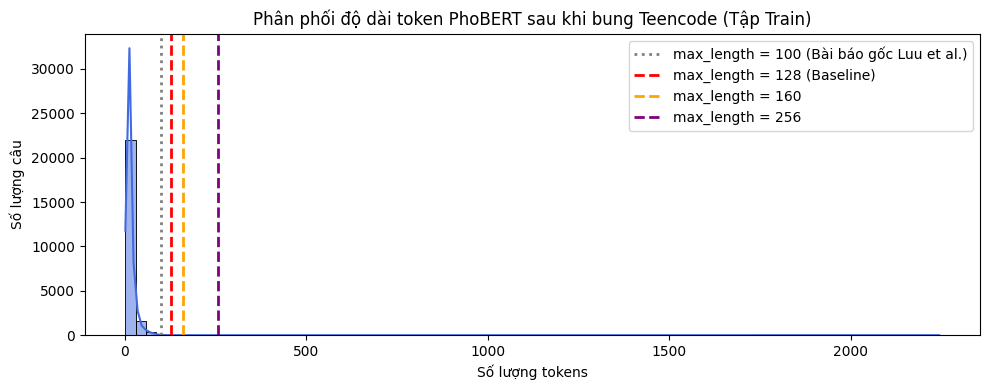

Cố định MAX_LENGTH = 128 để đối chứng cùng điều kiện tuyệt đối với Baseline gốc!


In [39]:
# 6. Khảo sát phân phối độ dài văn bản và tỷ lệ cắt cụt (truncation fraction)
print("Khởi tạo tokenizer vinai/phobert-base-v2 để đo lường độ dài token...")
survey_tok = AutoTokenizer.from_pretrained('vinai/phobert-base-v2', use_fast=False)

def analyze_token_distribution(texts, tok, thresholds=[100, 128, 160, 256]):
    lens = np.array([len(x) for x in tok(texts, truncation=False, padding=False)['input_ids']])
    stats = {
        'Tổng câu': len(lens),
        'Min': int(lens.min()),
        'Mean': round(float(lens.mean()), 2),
        'Median': int(np.median(lens)),
        'P95': int(np.percentile(lens, 95)),
        'P99': int(np.percentile(lens, 99)),
        'Max': int(lens.max())
    }
    for th in thresholds:
        cnt = int((lens > th).sum())
        pct = float((lens > th).mean() * 100)
        stats[f'> {th} tokens'] = f"{cnt} ({pct:.2f}%)"
    return stats, lens

stats_tr, lens_tr = analyze_token_distribution(processed[POLICY_NAME]['train'], survey_tok)
stats_dv, lens_dv = analyze_token_distribution(processed[POLICY_NAME]['dev'], survey_tok)
stats_te, lens_te = analyze_token_distribution(processed[POLICY_NAME]['test'], survey_tok)

df_dist = pd.DataFrame([
    dict(Split='Train', **stats_tr),
    dict(Split='Dev', **stats_dv),
    dict(Split='Test', **stats_te)
])
display(df_dist)
df_dist.to_csv(RUN_DIR / 'token_length_distribution.csv', index=False)

plt.figure(figsize=(10, 4))
sns.histplot(lens_tr, bins=80, kde=True, color='royalblue')
plt.axvline(100, color='gray', linestyle=':', linewidth=2, label='max_length = 100 (Bài báo gốc Luu et al.)')
plt.axvline(128, color='red', linestyle='--', linewidth=2, label='max_length = 128 (Baseline)')
plt.axvline(160, color='orange', linestyle='--', linewidth=2, label='max_length = 160')
plt.axvline(256, color='purple', linestyle='--', linewidth=2, label='max_length = 256')
plt.title("Phân phối độ dài token PhoBERT sau khi bung Teencode (Tập Train)")
plt.xlabel("Số lượng tokens"); plt.ylabel("Số lượng câu"); plt.legend(); plt.tight_layout()
plt.savefig(RUN_DIR / 'token_distribution.png', dpi=160)
plt.show(); plt.close()

# Giữ nguyên max_length = 128 cho thực nghiệm chính để so sánh ceteris paribus với baseline 68.20%
EXPERIMENT_MAX_LENGTH = 128
print(f"Cố định MAX_LENGTH = {EXPERIMENT_MAX_LENGTH} để đối chứng cùng điều kiện tuyệt đối với Baseline gốc!")


## 7. Khóa ngân sách và cấu hình thực nghiệm (JOBS)


In [35]:
# 7. Khóa ngân sách và cấu hình thực nghiệm (kế thừa cấu hình JOBS của notebook gốc)
JOBS = []
for seed in SEEDS:
    JOBS.append(dict(
        name='controlled_phobert_teencode_co_s42',
        model='vinai/phobert-base-v2',
        policy='shared_teencode_co',
        seed=seed,
        epochs=3,
        max_length=EXPERIMENT_MAX_LENGTH,
        lr=2e-5,
        warmup_ratio=0.0,
        weight_decay=0.01,
        selection='dev_macro_f1',
        batch=16,
        eval_batch=16,
        gradient_accumulation_steps=1,
        optimizer='adamw_torch',
        fp16=torch.cuda.is_available()
    ))

PLAN_HASH = hashlib.sha256(json.dumps(JOBS, sort_keys=True).encode()).hexdigest()
save_json('locked_experiment_plan.json', dict(jobs=JOBS, plan_sha256=PLAN_HASH, predeclared_seeds=SEEDS,
                                             total_epochs=sum(j['epochs'] for j in JOBS)))
display(pd.DataFrame(JOBS))


,name,model,policy,seed,epochs,max_length,lr,warmup_ratio,weight_decay,selection,batch,eval_batch,gradient_accumulation_steps,optimizer,fp16
0,controlled_phobert_teencode_co_s42,vinai/phobert-base-v2,shared_teencode_co,42,3,128,0.00002,0.0,0.01,dev_macro_f1,16,16,1,adamw_torch,True


## 8. Huấn luyện và chọn checkpoint — chưa đánh giá Test (y hệt notebook gốc)


In [36]:
# 8. Huấn luyện và chọn checkpoint — chưa đánh giá Test (Y HỆT Cell 14 của notebook gốc, tương thích 100%)
import shutil
trained = []

def tokenized_frame(texts, labels, tokenizer, max_length):
    d = {'text': texts}
    if labels is not None: d['labels'] = list(map(int, labels))
    ds = Dataset.from_dict(d)
    return ds.map(lambda b: tokenizer(b['text'], truncation=True, max_length=max_length),
                  batched=True, remove_columns=['text'])

def truncation_stats(texts, tokenizer, max_length):
    lens = [len(x) for x in tokenizer(texts, truncation=False, padding=False)['input_ids']]
    return dict(rows=len(lens), fraction_truncated=float(np.mean(np.array(lens) > max_length)),
                mean_tokens=float(np.mean(lens)), max_tokens=int(max(lens)))

def hf_metrics(p):
    logits = p.predictions[0] if isinstance(p.predictions, tuple) else p.predictions
    return metrics(p.label_ids, np.argmax(logits, axis=-1))

def train_job(job):
    set_seed(job['seed'])
    work = RUN_DIR / job['name']; work.mkdir(exist_ok=False)
    tokenizer = AutoTokenizer.from_pretrained(job['model'], use_fast=False)
    tokenizer_revision = tokenizer.init_kwargs.get('_commit_hash')
    t = time.perf_counter()
    
    # Đảm bảo nạp đúng policy từ processed
    policy_key = job['policy']
    if policy_key not in processed and len(processed) == 1:
        policy_key = list(processed.keys())[0]
        
    tr = tokenized_frame(processed[policy_key]['train'], y_train, tokenizer, job['max_length'])
    dv = tokenized_frame(processed[policy_key]['dev'], y_dev, tokenizer, job['max_length'])
    token_s = time.perf_counter() - t
    trunc = {s: truncation_stats(processed[policy_key][s], tokenizer, job['max_length']) for s in ['train', 'dev']}
    
    model = AutoModelForSequenceClassification.from_pretrained(
        job['model'], num_labels=3,
        id2label=dict(enumerate(NAMES)), label2id=dict(zip(NAMES, LABELS))
    )
    revision = getattr(model.config, '_commit_hash', None)
    best = job['selection'] == 'dev_macro_f1'
    
    # Hỗ trợ linh hoạt cả eval_strategy (transformers mới) và evaluation_strategy (transformers cũ)
    strategy_args = {}
    try:
        TrainingArguments(output_dir=str(work / 'tmp_test'), eval_strategy='no')
        strategy_args['eval_strategy'] = 'epoch' if best else 'no'
    except TypeError:
        strategy_args['evaluation_strategy'] = 'epoch' if best else 'no'
    if (work / 'tmp_test').exists():
        shutil.rmtree(work / 'tmp_test')
        
    args = TrainingArguments(
        output_dir=str(work / 'checkpoints'),
        save_strategy='epoch' if best else 'no',
        logging_strategy='epoch',
        per_device_train_batch_size=job['batch'],
        per_device_eval_batch_size=job['eval_batch'],
        gradient_accumulation_steps=1,
        num_train_epochs=job['epochs'],
        learning_rate=job['lr'],
        warmup_ratio=job['warmup_ratio'],
        weight_decay=job['weight_decay'],
        optim=job['optimizer'],
        adam_beta1=0.9, adam_beta2=0.999, adam_epsilon=1e-8, max_grad_norm=1.0,
        lr_scheduler_type='linear', fp16=torch.cuda.is_available(), seed=job['seed'], data_seed=job['seed'],
        report_to='none', save_total_limit=1,
        load_best_model_at_end=best, metric_for_best_model='macro_f1' if best else None,
        greater_is_better=True if best else None, dataloader_num_workers=0,
        **strategy_args
    )
    
    # Hỗ trợ cả processing_class và tokenizer
    trainer_kwargs = dict(
        model=model, args=args, train_dataset=tr, eval_dataset=dv,
        data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=hf_metrics
    )
    try:
        trainer = Trainer(**trainer_kwargs, processing_class=tokenizer)
    except TypeError:
        trainer = Trainer(**trainer_kwargs, tokenizer=tokenizer)
        
    if torch.cuda.is_available():
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t = time.perf_counter(); trainer.train(); torch.cuda.synchronize() if torch.cuda.is_available() else None; train_s = time.perf_counter() - t
    peak = torch.cuda.max_memory_allocated() / 1024**3 if torch.cuda.is_available() else 0.0
    dev_output = trainer.predict(dv); dev_pred = np.argmax(dev_output.predictions, axis=-1)
    selected = work / 'selected_model'; trainer.save_model(str(selected)); tokenizer.save_pretrained(str(selected))
    row = {
        **job, 'model_revision': revision, 'tokenizer_revision': tokenizer_revision,
        'tokenization_train_dev_s': token_s, 'train_with_dev_checkpoint_s': train_s,
        'peak_gpu_allocated_gib': peak, 'dev_metrics': metrics(y_dev, dev_pred),
        'best_checkpoint': trainer.state.best_model_checkpoint, 'selected_model': str(selected),
        'truncation': trunc
    }
    (work / 'run.json').write_text(json.dumps(row, ensure_ascii=False, indent=2), encoding='utf-8')
    (work / 'history.json').write_text(json.dumps(trainer.state.log_history, indent=2), encoding='utf-8')
    print(job['name'], row['dev_metrics'])
    display(pd.DataFrame(trainer.state.log_history))
    del trainer, model, tr, dv; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    checkpoint_dir = work / 'checkpoints'
    if checkpoint_dir.exists(): shutil.rmtree(checkpoint_dir)
    return row

for job in JOBS:
    trained.append(train_job(job))
    save_json('trained_jobs.json', trained)


Map:   0%|          | 0/24048 [00:00<?, ? examples/s]

Map:   0%|          | 0/2672 [00:00<?, ? examples/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at vinai/phobert-base-v2 and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Macro F1,Weighted F1,Accuracy,F1 Clean,F1 Offensive,F1 Hate
1,0.400600,0.460640,0.569262,0.832733,0.862275,0.927425,0.287823,0.492537
2,0.287100,0.401453,0.673014,0.867422,0.874251,0.937304,0.465753,0.615984
3,0.218800,0.415128,0.682143,0.871439,0.874626,0.939524,0.481675,0.625229


controlled_phobert_teencode_co_s42 {'macro_f1': 0.6821427535588805, 'weighted_f1': 0.8714390745975668, 'accuracy': 0.874625748502994, 'f1_CLEAN': 0.939524348810872, 'f1_OFFENSIVE': 0.4816753926701571, 'f1_HATE': 0.6252285191956124}


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_macro_f1,eval_weighted_f1,eval_accuracy,eval_f1_CLEAN,eval_f1_OFFENSIVE,eval_f1_HATE,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.4006,11.442142,1.335108e-05,1.0,1503,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,1503,0.460640,0.569262,0.832733,0.862275,0.927425,0.287823,0.492537,2.7206,982.119,61.382,NaN,NaN,NaN,NaN,NaN
2,0.2871,5.552874,6.684409e-06,2.0,3006,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,3006,0.401453,0.673014,0.867422,0.874251,0.937304,0.465753,0.615984,3.4672,770.643,48.165,NaN,NaN,NaN,NaN,NaN
4,0.2188,20.034225,1.774229e-08,3.0,4509,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,4509,0.415128,0.682143,0.871439,0.874626,0.939524,0.481675,0.625229,2.7769,962.236,60.140,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,3.0,4509,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,669.7929,107.711,6.732,1.705427e+15,0.302166


## 9. Khóa mô hình rồi đánh giá Test (y hệt notebook gốc)


Map:   0%|          | 0/6680 [00:00<?, ? examples/s]

controlled_phobert_teencode_co_s42


,precision,recall,f1-score,support
CLEAN,0.931694,0.948991,0.940263,5548.000000
OFFENSIVE,0.477212,0.400901,0.435741,444.000000
HATE,0.643293,0.613372,0.627976,688.000000
accuracy,0.877994,0.877994,0.877994,0.877994
macro avg,0.684066,0.654421,0.667993,6680.000000
weighted avg,0.871782,0.877994,0.874565,6680.000000


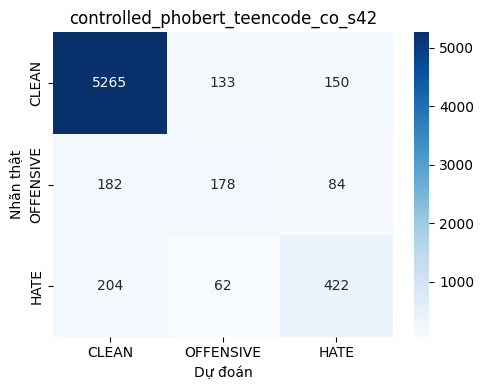

,name,model,policy,seed,macro_f1,weighted_f1,accuracy,f1_CLEAN,f1_OFFENSIVE,f1_HATE,dev_macro_f1,train_s,test_tokenize_s,test_predict_s,peak_gpu_gib
0,controlled_phobert_teencode_co_s42,vinai/phobert-base-v2,shared_teencode_co,42,0.667993,0.874565,0.877994,0.940263,0.435741,0.627976,0.682143,670.260083,2.712988,20.843312,2.564653


PosixPath('vihsd_teencode_co_experiment/20261112_181137/predictions.csv')

In [37]:
# 9. Khóa mô hình rồi đánh giá Test (Y HỆT Cell 16 của notebook gốc)
assert hashlib.sha256(json.dumps(JOBS, sort_keys=True).encode()).hexdigest() == PLAN_HASH
assert len(trained) == len(JOBS)
save_json('locked_test_models.json', [dict(name=r['name'], selected_model=r['selected_model'], selection=r['selection']) for r in trained])

y_test = df_test.label.to_numpy(); predictions = {}; test_rows = []
for row in trained:
    tokenizer = AutoTokenizer.from_pretrained(row['selected_model'], use_fast=False)
    policy_key = row['policy'] if row['policy'] in processed else list(processed.keys())[0]
    t = time.perf_counter(); ds = tokenized_frame(processed[policy_key]['test'], None, tokenizer, row['max_length'])
    token_s = time.perf_counter() - t
    model = AutoModelForSequenceClassification.from_pretrained(row['selected_model']).to('cuda' if torch.cuda.is_available() else 'cpu')
    model.eval()
    loader = torch.utils.data.DataLoader(ds, batch_size=row['eval_batch'], shuffle=False, collate_fn=DataCollatorWithPadding(tokenizer))
    pred = []
    if torch.cuda.is_available(): torch.cuda.synchronize()
    t = time.perf_counter()
    with torch.inference_mode():
        for batch in loader:
            if torch.cuda.is_available(): batch = {k: v.to('cuda') for k, v in batch.items()}
            pred.extend(model(**batch).logits.argmax(-1).cpu().tolist())
    if torch.cuda.is_available(): torch.cuda.synchronize()
    infer_s = time.perf_counter() - t
    pred = np.asarray(pred); assert len(pred) == len(df_test)
    predictions[row['name']] = pred
    test_rows.append(dict(name=row['name'], model=row['model'], policy=row['policy'], seed=row['seed'],
                          **metrics(y_test, pred), dev_macro_f1=row['dev_metrics']['macro_f1'],
                          train_s=row['train_with_dev_checkpoint_s'], test_tokenize_s=token_s, test_predict_s=infer_s,
                          peak_gpu_gib=row['peak_gpu_allocated_gib']))
    output = pd.DataFrame(dict(id=df_test.id, text=df_test.text, ground_truth=y_test, predicted_label=pred))
    assert list(output.columns) == ['id', 'text', 'ground_truth', 'predicted_label'] and output.id.is_unique
    output.to_csv(RUN_DIR / f"predictions_{row['name']}.csv", index=False, encoding='utf-8-sig')
    report = classification_report(y_test, pred, labels=LABELS, target_names=NAMES, zero_division=0, output_dict=True)
    save_json(f"report_{row['name']}.json", report)
    print(row['name']); display(pd.DataFrame(report).T)
    cm = confusion_matrix(y_test, pred, labels=LABELS)
    pd.DataFrame(cm, index=NAMES, columns=NAMES).to_csv(RUN_DIR / f"cm_{row['name']}.csv")
    plt.figure(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt='d', xticklabels=NAMES, yticklabels=NAMES, cmap='Blues')
    plt.xlabel('Dự đoán'); plt.ylabel('Nhãn thật'); plt.title(row['name']); plt.tight_layout()
    plt.savefig(RUN_DIR / f"cm_{row['name']}.png", dpi=160); plt.show(); plt.close()
    del model, loader, ds; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

comparison = pd.DataFrame(test_rows); comparison.to_csv(RUN_DIR / 'test_comparison.csv', index=False)
display(comparison)
shutil.copy2(RUN_DIR / f"predictions_{trained[0]['name']}.csv", RUN_DIR / 'predictions.csv')


## 10. Đánh giá chống rò rỉ dữ liệu (Unseen Test) & Bảng đối chứng Ablation Gain


In [38]:
# 10. Đánh giá chống rò rỉ dữ liệu (Unseen Test) & Bảng đối chứng Ablation Gain (kế thừa Cell 18)
subset_rows = []
for row in trained:
    name = row['name']
    pred = predictions[name]
    if UNSEEN_MASK.any():
        subset_rows.append(dict(
            name=name, rows=int(UNSEEN_MASK.sum()),
            **metrics(y_test[UNSEEN_MASK], pred[UNSEEN_MASK])
        ))

df_unseen = pd.DataFrame(subset_rows)
display(df_unseen)
df_unseen.to_csv(RUN_DIR / 'test_unseen_text.csv', index=False)

# Bảng so sánh Ablation Gain đối chứng với Baseline cũ
curr_full_f1 = float(comparison['macro_f1'].iloc[0])
curr_unseen_f1 = float(df_unseen['macro_f1'].iloc[0])

ablation_table = pd.DataFrame([
    {
        'Phương pháp': 'PhoBERT Baseline (Không Teencode)',
        'Macro F1 Full Test (%)': BASELINE_FULL_MACRO_F1 * 100,
        'Macro F1 Unseen Test (%)': BASELINE_UNSEEN_MACRO_F1 * 100,
        'Gain Full (pp)': 0.00,
        'Gain Unseen (pp)': 0.00
    },
    {
        'Phương pháp': f"PhoBERT + {trained[0]['name']}",
        'Macro F1 Full Test (%)': round(curr_full_f1 * 100, 2),
        'Macro F1 Unseen Test (%)': round(curr_unseen_f1 * 100, 2),
        'Gain Full (pp)': round((curr_full_f1 - BASELINE_FULL_MACRO_F1) * 100, 2),
        'Gain Unseen (pp)': round((curr_unseen_f1 - BASELINE_UNSEEN_MACRO_F1) * 100, 2)
    }
])

print("=== BẢNG TỔNG HỢP ABLATION GAIN ===")
display(ablation_table)
ablation_table.to_csv(RUN_DIR / 'ablation_summary.csv', index=False)

# Đóng gói ZIP báo cáo
zip_archive = f"{trained[0]['name']}_reports"
shutil.make_archive(str(ROOT / zip_archive), 'zip', RUN_DIR)
print(f"Báo cáo và các file xuất ra đã nén tại: {ROOT / (zip_archive + '.zip')}")


,name,rows,macro_f1,weighted_f1,accuracy,f1_CLEAN,f1_OFFENSIVE,f1_HATE
0,controlled_phobert_teencode_co_s42,5796,0.664236,0.868414,0.872671,0.937266,0.42047,0.634972


=== BẢNG TỔNG HỢP ABLATION GAIN ===


,Phương pháp,Macro F1 Full Test (%),Macro F1 Unseen Test (%),Gain Full (pp),Gain Unseen (pp)
0,PhoBERT Baseline (Không Teencode),68.2,67.58,0.0,0.00
1,PhoBERT + controlled_phobert_teencode_co_s42,66.8,66.42,-1.4,-1.16


Báo cáo và các file xuất ra đã nén tại: vihsd_teencode_co_experiment/controlled_phobert_teencode_co_s42_reports.zip
